# PrédiVol : collecte, exploration et préparation des données


## 0. Paramètres

In [1]:
# ===== PARAMÈTRES (modifiez seulement ici) =====
DOSSIER_DONNEES = None    # None = téléchargement automatique depuis Kaggle
                          # sinon, chemin du dossier qui contient les CSV (ex. "/content/drive/MyDrive/predivol")
FRACTION = 1.0            # 1.0 = tous les vols ; mettez 0.3 si Colab manque de mémoire (30 % des vols au hasard)
GRAINE = 42

In [2]:
import os, re, glob, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
os.makedirs("figures", exist_ok=True)
BLEU, ORANGE, ROUGE = "#3b5ba5", "#e07b24", "#c0392b"

def sauver(nom):
    plt.tight_layout()
    plt.savefig(f"figures/{nom}.png", dpi=130, bbox_inches="tight")
    plt.show()

## 1. Téléchargement des données

Le téléchargement automatique utilise `kagglehub`. S'il échoue (par exemple parce que Kaggle demande une connexion) :
1. téléchargez le jeu sur [la page Kaggle](https://www.kaggle.com/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft) (bouton *Download*) ;
2. décompressez-le dans votre Google Drive ;
3. montez le Drive dans Colab (icône de dossier à gauche, puis *Monter Drive*) et indiquez le dossier dans `DOSSIER_DONNEES`.

In [3]:
if DOSSIER_DONNEES is None:
    try:
        import kagglehub
    except ImportError:
        %pip -q install kagglehub
        import kagglehub
    DOSSIER_DONNEES = kagglehub.dataset_download("bordanova/2023-us-civil-flights-delay-meteo-and-aircraft")

print("Dossier :", DOSSIER_DONNEES)
fichiers = sorted(glob.glob(os.path.join(DOSSIER_DONNEES, "**", "*.csv"), recursive=True))
for f in fichiers:
    print(f"{os.path.getsize(f)/1e6:9.1f} Mo   {os.path.basename(f)}")

def choisir(motcle):
    trouves = [f for f in fichiers if motcle in os.path.basename(f).lower()]
    return trouves[0] if trouves else None

F_VOLS = choisir("us_flights_2023") or choisir("flights")
F_METEO = choisir("weather")
F_ANNULES = choisir("cancel")
print("\nVols    :", F_VOLS)
print("Météo   :", F_METEO)
print("Annulés :", F_ANNULES)
assert F_VOLS, "Fichier des vols introuvable : vérifiez DOSSIER_DONNEES."

100%|██████████| 127M/127M [00:01<00:00, 102MB/s]

Extracting files...


Dossier : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9
     18.7 Mo   Cancelled_Diverted_2023.csv
   1151.9 Mo   US_flights_2023.csv
      0.0 Mo   airports_geolocation.csv
     90.1 Mo   maj us flight - january 2024.csv
      7.4 Mo   weather_meteo_by_airport.csv

Vols    : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/US_flights_2023.csv
Météo   : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/weather_meteo_by_airport.csv
Annulés : /root/.cache/kagglehub/datasets/bordanova/2023-us-civil-flights-delay-meteo-and-aircraft/versions/9/Cancelled_Diverted_2023.csv


In [4]:
rng = np.random.default_rng(GRAINE)
lignes_a_sauter = (lambda i: i > 0 and rng.random() > FRACTION) if FRACTION < 1 else None
vols = pd.read_csv(F_VOLS, low_memory=False, skiprows=lignes_a_sauter)

# Les colonnes texte répétitives deviennent des catégories (beaucoup moins de mémoire)
for c in vols.select_dtypes("object").columns:
    if vols[c].nunique() < 0.5 * len(vols):
        vols[c] = vols[c].astype("category")

print(f"{len(vols):,} vols × {vols.shape[1]} colonnes – mémoire : {vols.memory_usage(deep=True).sum()/1e9:.2f} Go")
print("\nColonnes :", list(vols.columns))
vols.head()

6,743,404 vols × 24 colonnes – mémoire : 0.72 Go

Colonnes : ['FlightDate', 'Day_Of_Week', 'Airline', 'Tail_Number', 'Dep_Airport', 'Dep_CityName', 'DepTime_label', 'Dep_Delay', 'Dep_Delay_Tag', 'Dep_Delay_Type', 'Arr_Airport', 'Arr_CityName', 'Arr_Delay', 'Arr_Delay_Type', 'Flight_Duration', 'Distance_type', 'Delay_Carrier', 'Delay_Weather', 'Delay_NAS', 'Delay_Security', 'Delay_LastAircraft', 'Manufacturer', 'Model', 'Aicraft_age']


,FlightDate,Day_Of_Week,Airline,Tail_Number,Dep_Airport,Dep_CityName,DepTime_label,Dep_Delay,Dep_Delay_Tag,Dep_Delay_Type,Arr_Airport,Arr_CityName,Arr_Delay,Arr_Delay_Type,Flight_Duration,Distance_type,Delay_Carrier,Delay_Weather,Delay_NAS,Delay_Security,Delay_LastAircraft,Manufacturer,Model,Aicraft_age
0,2023-01-02,1,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-3,0,Low <5min,LGA,"New York, NY",-12,Low <5min,56,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
1,2023-01-03,2,Endeavor Air,N605LR,BDL,"Hartford, CT",Morning,-5,0,Low <5min,LGA,"New York, NY",-8,Low <5min,62,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,16
2,2023-01-04,3,Endeavor Air,N331PQ,BDL,"Hartford, CT",Morning,-5,0,Low <5min,LGA,"New York, NY",-21,Low <5min,49,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10
3,2023-01-05,4,Endeavor Air,N906XJ,BDL,"Hartford, CT",Morning,-6,0,Low <5min,LGA,"New York, NY",-17,Low <5min,54,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,17
4,2023-01-06,5,Endeavor Air,N337PQ,BDL,"Hartford, CT",Morning,-1,0,Low <5min,LGA,"New York, NY",-16,Low <5min,50,Short Haul >1500Mi,0,0,0,0,0,CANADAIR REGIONAL JET,CRJ,10


## 2. Repérage automatique des colonnes

Les noms exacts des colonnes ne sont pas garantis : cette cellule les retrouve. Si une ligne affiche `None` alors que la colonne existe, écrivez son nom à la main, par exemple `C["avion"] = "Tail_Number"`.

In [5]:
def norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def trouver(df, *candidats):
    index = {norm(c): c for c in df.columns}
    for cand in candidats:
        if norm(cand) in index:
            return index[norm(cand)]
    return None

C = dict(
    date=trouver(vols, "FlightDate", "FL_DATE", "Flight_Date", "Date"),
    compagnie=trouver(vols, "Airline", "Carrier", "OP_UNIQUE_CARRIER", "Reporting_Airline"),
    avion=trouver(vols, "Tail_Number", "TailNum", "Tail_Num"),
    dep=trouver(vols, "Dep_Airport", "Origin", "ORIGIN_AIRPORT", "Origin_Airport"),
    arr=trouver(vols, "Arr_Airport", "Dest", "DESTINATION_AIRPORT", "Dest_Airport"),
    heure=trouver(vols, "CRS_Dep_Time", "CRSDepTime", "Scheduled_Departure", "DepTime_label", "Dep_Time_Blk", "DEP_TIME_BLK"),
    cible=trouver(vols, "Arr_Delay", "ARRIVAL_DELAY", "ArrDelay"),
    dep_delay=trouver(vols, "Dep_Delay", "DEPARTURE_DELAY", "DepDelay"),
    distance=trouver(vols, "Distance", "Distance_type", "DISTANCE"),
    duree=trouver(vols, "Flight_Duration", "CRS_Elapsed_Time", "Scheduled_Time"),
    age=trouver(vols, "Aicraft_age", "Aircraft_age", "Aircraft_Age"),
    constructeur=trouver(vols, "Manufacturer"),
    modele=trouver(vols, "Model"),
)
for k, v in C.items():
    print(f"{k:13s} -> {v}")
assert C["cible"], "Colonne du retard à l'arrivée introuvable : écrivez son nom, ex. C['cible'] = 'Arr_Delay'"
assert C["date"], "Colonne de date introuvable : écrivez son nom, ex. C['date'] = 'FlightDate'"

# Colonnes connues seulement APRÈS le départ = fuite de données (exclues des modèles)
FUITE = [c for c in vols.columns if c != C["cible"] and re.search(
    r"dep_?delay|^delay_|_delay$|delay_?(type|tag|group)|del15|taxi|wheels|air_?time|actual|^elapsed", c, re.I)]
print("\nFuite de données (exclues des modèles) :", FUITE)
print("À vérifier : la durée", C["duree"], "et l'heure", C["heure"],
      "sont-elles PRÉVUES (utilisables) ou RÉELLES (fuite) ? Regardez la documentation Kaggle.")

date          -> FlightDate
compagnie     -> Airline
avion         -> Tail_Number
dep           -> Dep_Airport
arr           -> Arr_Airport
heure         -> DepTime_label
cible         -> Arr_Delay
dep_delay     -> Dep_Delay
distance      -> Distance_type
duree         -> Flight_Duration
age           -> Aicraft_age
constructeur  -> Manufacturer
modele        -> Model

Fuite de données (exclues des modèles) : ['Dep_Delay', 'Dep_Delay_Tag', 'Dep_Delay_Type', 'Arr_Delay_Type', 'Delay_Carrier', 'Delay_Weather', 'Delay_NAS', 'Delay_Security', 'Delay_LastAircraft']
À vérifier : la durée Flight_Duration et l'heure DepTime_label sont-elles PRÉVUES (utilisables) ou RÉELLES (fuite) ? Regardez la documentation Kaggle.


## 3. Aperçu : types, valeurs manquantes, doublons

In [6]:
apercu = pd.DataFrame({
    "type": vols.dtypes.astype(str),
    "manquantes_%": (vols.isna().mean() * 100).round(2),
    "valeurs_distinctes": vols.nunique(),
    "exemple": vols.iloc[0],
})
apercu["role"] = np.where(apercu.index == C["cible"], "CIBLE", np.where(apercu.index.isin(FUITE), "fuite (exclue)", ""))
display(apercu)

nb_doublons = int(vols.duplicated().sum())
vols["_date"] = pd.to_datetime(vols[C["date"]], errors="coerce").dt.normalize()
print("Nombre de vols", ":", f"{len(vols):,}")
print("Nombre de colonnes", ":", vols.shape[1] - 1)
print("Période", ":", f"{vols['_date'].min():%Y-%m-%d} au {vols['_date'].max():%Y-%m-%d}")
print("Colonnes avec valeurs manquantes", ":", ", ".join(f"{i} ({v} %)" for i, v in apercu["manquantes_%"].items() if v > 0) or "aucune")
print("Doublons :", nb_doublons)

,type,manquantes_%,valeurs_distinctes,exemple,role
FlightDate,category,0.0,365,2023-01-02,
Day_Of_Week,int64,0.0,7,1,
Airline,category,0.0,15,Endeavor Air,
Tail_Number,category,0.0,5963,N605LR,
Dep_Airport,category,0.0,350,BDL,
Dep_CityName,category,0.0,344,"Hartford, CT",
DepTime_label,category,0.0,4,Morning,
Dep_Delay,int64,0.0,1854,-3,fuite (exclue)
Dep_Delay_Tag,int64,0.0,2,0,fuite (exclue)
Dep_Delay_Type,category,0.0,3,Low <5min,fuite (exclue)


Nombre de vols : 6,743,404
Nombre de colonnes : 24
Période : 2023-01-01 au 2023-12-31
Colonnes avec valeurs manquantes : aucune
Doublons : 31


## 4. La cible : retard à l'arrivée (minutes)

Valeur négative = arrivée en avance. On regarde la forme de la distribution et les valeurs extrêmes.

,retard à l'arrivée (min)
count,6743404.0
mean,6.6
std,57.1
min,-119.0
5%,-27.0
25%,-15.0
50%,-6.0
75%,9.0
90%,41.0
95%,78.0


Retard moyen (min) : 6.6
Retard médian (min) : -6.0
% vols en avance : 61.5
% vols avec 15 min de retard ou plus : 20.6
% vols avec 60 min de retard ou plus : 6.9
Retard maximal (min) : 4405
Asymétrie (skewness) : 10.93


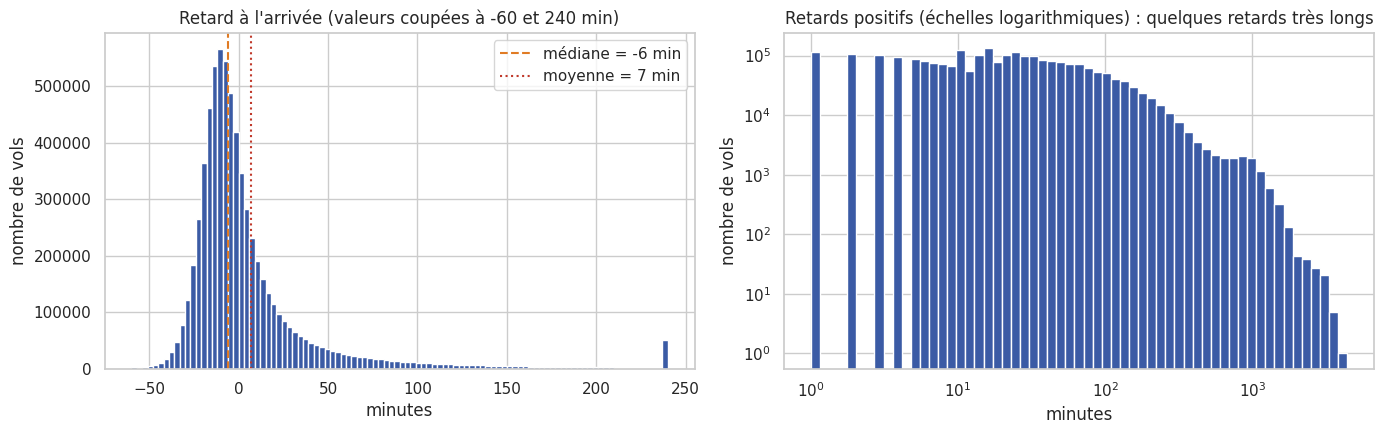

In [7]:
y = vols[C["cible"]].dropna()
display(y.describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]).round(1).to_frame("retard à l'arrivée (min)"))

print("Retard moyen (min)", ":", round(y.mean(), 1))
print("Retard médian (min)", ":", round(y.median(), 1))
print("% vols en avance", ":", round((y < 0).mean() * 100, 1))
print("% vols avec 15 min de retard ou plus", ":", round((y >= 15).mean() * 100, 1))
print("% vols avec 60 min de retard ou plus", ":", round((y >= 60).mean() * 100, 1))
print("Retard maximal (min)", ":", int(y.max()))
print("Asymétrie (skewness)", ":", round(y.skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(y.clip(-60, 240), bins=100, color=BLEU)
ax[0].axvline(y.median(), color=ORANGE, ls="--", label=f"médiane = {y.median():.0f} min")
ax[0].axvline(y.mean(), color=ROUGE, ls=":", label=f"moyenne = {y.mean():.0f} min")
ax[0].set(title="Retard à l'arrivée (valeurs coupées à -60 et 240 min)", xlabel="minutes", ylabel="nombre de vols")
ax[0].legend()
pos = y[y > 0]
ax[1].hist(pos, bins=np.logspace(0, np.log10(pos.max() + 1), 60), color=BLEU)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set(title="Retards positifs (échelles logarithmiques) : quelques retards très longs", xlabel="minutes", ylabel="nombre de vols")
sauver("01_distribution_retard")

## 5. Variables dérivées

Toutes ces variables sont **connues avant le départ** (pas de fuite de données) :
- le mois, le jour de la semaine et le moment de la journée ;
- l'**effet domino** : le nombre de vols du même avion ce jour-là ;
- le **trafic prévu** : le nombre de vols programmés ce jour-là à l'aéroport de départ et à l'aéroport d'arrivée (mesure de la congestion) ;
- la **proximité d'un jour férié** américain (Thanksgiving, Noël, 4 juillet…).

In [8]:
vols["mois"] = vols["_date"].dt.month
vols["jour_semaine"] = vols["_date"].dt.dayofweek + 1          # 1 = lundi … 7 = dimanche

h = C["heure"]
if h is not None and pd.api.types.is_numeric_dtype(vols[h]):
    vols["heure_dep"] = (vols[h] // 100).clip(0, 23)            # format HHMM -> heure
    vols["tranche"] = pd.cut(vols["heure_dep"], [-1, 5, 11, 17, 21, 23],
                             labels=["nuit", "matin", "après-midi", "soir", "nuit tardive"])
elif h is not None:
    vols["tranche"] = vols[h].astype("category")                 # étiquette déjà fournie (ex. Morning)

# Effet domino : nombre de vols du même avion le même jour (connu dans le planning avant le départ)
if C["avion"]:
    vols["vols_jour_avion"] = vols.groupby([C["avion"], "_date"], observed=True)[C["cible"]].transform("size").astype("float32")
    if "heure_dep" in vols:
        vols["rang_vol_jour"] = vols.groupby([C["avion"], "_date"], observed=True)["heure_dep"].rank(method="first").astype("float32")
    print(vols["vols_jour_avion"].describe().round(2))
else:
    print("Pas de numéro d'avion : l'effet domino ne peut pas être calculé.")

count    6743404.00
mean           4.80
std            1.63
min            1.00
25%            4.00
50%            5.00
75%            6.00
max           13.00
Name: vols_jour_avion, dtype: float64


In [9]:
# Trafic prévu : vols programmés le même jour au même aéroport (les vols annulés font aussi partie du planning)
planning = pd.DataFrame({"dep": vols[C["dep"]].astype(str), "arr": vols[C["arr"]].astype(str), "_date": vols["_date"]})
if F_ANNULES:
    try:
        ann = pd.read_csv(F_ANNULES, low_memory=False)
        a_dep, a_arr, a_date = trouver(ann, C["dep"]), trouver(ann, C["arr"]), trouver(ann, C["date"])
        if a_dep and a_arr and a_date:
            ann = pd.DataFrame({"dep": ann[a_dep].astype(str), "arr": ann[a_arr].astype(str),
                                "_date": pd.to_datetime(ann[a_date], errors="coerce").dt.normalize()})
            if FRACTION < 1:
                ann = ann.sample(frac=FRACTION, random_state=GRAINE)
            planning = pd.concat([planning, ann], ignore_index=True)
            print(f"Vols annulés ou déroutés ajoutés au planning : {len(ann):,}")
    except Exception as e:
        print("Fichier des annulés non utilisé :", e)

for cote in ["dep", "arr"]:
    par_jour = planning.groupby([cote, "_date"]).size()
    cle = pd.MultiIndex.from_arrays([vols[C[cote]].astype(str), vols["_date"]])
    vols[f"trafic_{cote}_jour"] = (par_jour.reindex(cle).to_numpy(dtype="float64") / FRACTION).astype("float32")
print(vols[["trafic_dep_jour", "trafic_arr_jour"]].describe().round(0))

# Jours fériés américains : nombre de jours jusqu'au jour férié le plus proche (plafonné à 15)
FERIES_2023 = ["2023-01-01", "2023-01-02", "2023-01-16", "2023-02-20", "2023-05-29", "2023-06-19", "2023-07-04",
               "2023-09-04", "2023-10-09", "2023-11-10", "2023-11-11", "2023-11-23", "2023-12-25"]
annees = sorted(int(a) for a in vols["_date"].dt.year.dropna().unique())
try:
    import holidays
    feries = pd.to_datetime([d for a in range(annees[0] - 1, annees[-1] + 2) for d in holidays.US(years=a).keys()])
    print("Jours fériés : bibliothèque holidays")
except Exception:
    feries = pd.to_datetime(FERIES_2023)
    print("Jours fériés : liste 2023 intégrée")
feries = np.sort(feries.values.astype("datetime64[D]"))
jours = vols["_date"].values.astype("datetime64[D]")
pos = np.searchsorted(feries, jours)
avant = feries[np.clip(pos - 1, 0, len(feries) - 1)]
apres = feries[np.clip(pos, 0, len(feries) - 1)]
ecart = np.minimum(np.abs((jours - avant).astype("int64")), np.abs((apres - jours).astype("int64"))).astype("float32")
ecart[vols["_date"].isna().to_numpy()] = np.nan
vols["jours_ferie"] = np.clip(ecart, 0, 15)
print(f"Vols à 3 jours ou moins d'un jour férié : {(vols['jours_ferie'] <= 3).mean() * 100:.1f} %")

Vols annulés ou déroutés ajoutés au planning : 104,488
       trafic_dep_jour  trafic_arr_jour
count        6743404.0        6743404.0
mean             350.0            350.0
std              266.0            266.0
min                1.0              1.0
25%              121.0            121.0
50%              305.0            305.0
75%              512.0            512.0
max             1030.0           1030.0
Jours fériés : bibliothèque holidays
Vols à 3 jours ou moins d'un jour férié : 21.3 %


## 6. Quand et où les retards sont-ils les plus forts ?

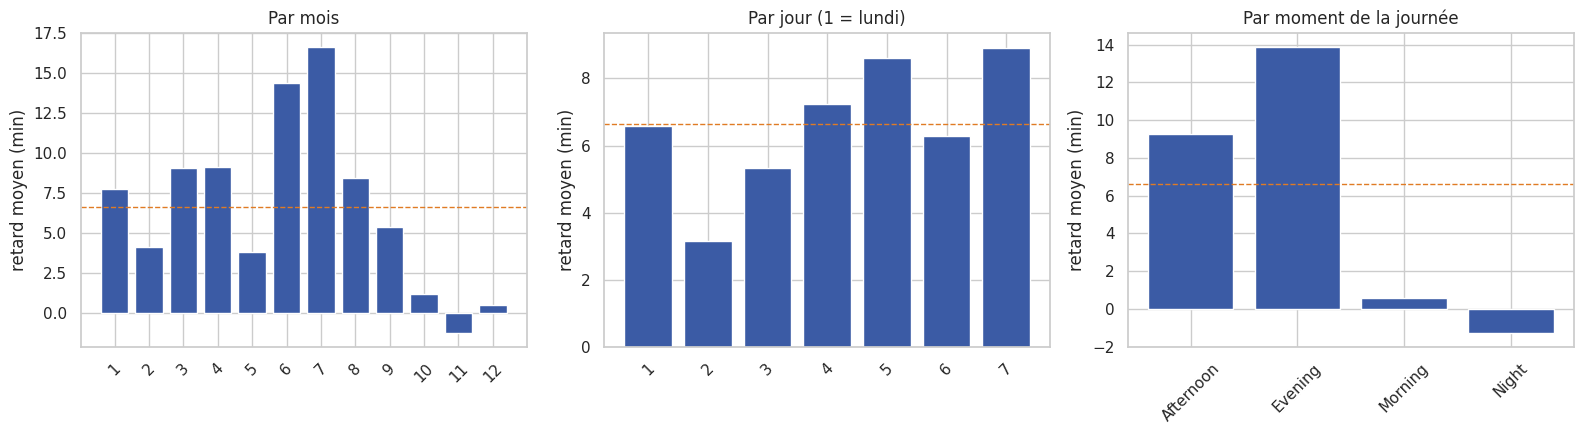

Mois le plus en retard : 7 (16.6 min en moyenne)
Mois le moins en retard : 11 (-1.3 min en moyenne)


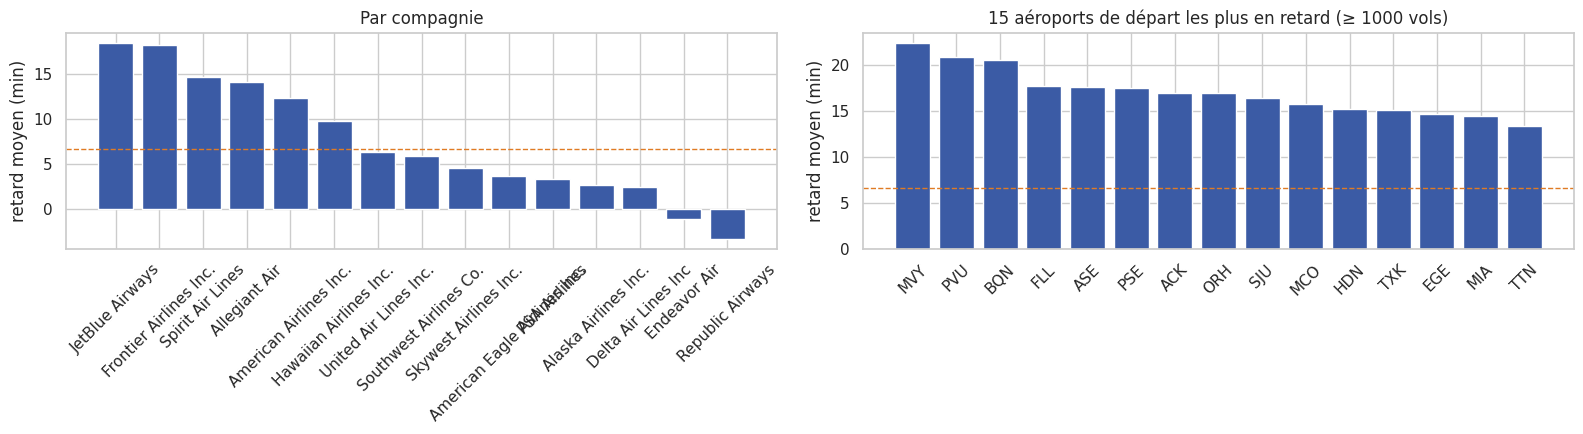

Compagnie la plus en retard : JetBlue Airways (18.5 min)
Aéroport de départ le plus en retard : MVY (22.4 min)


In [10]:
MIN_VOLS = 1000 if len(vols) > 1_000_000 else 100

def profil(col, titre, ax, ordre=None, top=None, min_vols=0):
    g = vols.groupby(col, observed=True)[C["cible"]].agg(["mean", "count"])
    g = g[g["count"] >= min_vols]
    if top:
        g = g.sort_values("mean", ascending=False).head(top)
    elif ordre is not None:
        g = g.reindex([o for o in ordre if o in g.index])
    ax.bar(g.index.astype(str), g["mean"], color=BLEU)
    ax.axhline(vols[C["cible"]].mean(), color=ORANGE, ls="--", lw=1)
    ax.set(title=titre, ylabel="retard moyen (min)")
    ax.tick_params(axis="x", rotation=45)
    return g

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
g_mois = profil("mois", "Par mois", ax[0], ordre=range(1, 13))
profil("jour_semaine", "Par jour (1 = lundi)", ax[1], ordre=range(1, 8))
if "tranche" in vols:
    g_tr = profil("tranche", "Par moment de la journée", ax[2])
sauver("02_retard_par_periode")
print("Mois le plus en retard", ":", f"{int(g_mois['mean'].idxmax())} ({g_mois['mean'].max():.1f} min en moyenne)")
print("Mois le moins en retard", ":", f"{int(g_mois['mean'].idxmin())} ({g_mois['mean'].min():.1f} min en moyenne)")

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
g_cie = profil(C["compagnie"], "Par compagnie", ax[0], top=30)
g_aer = profil(C["dep"], f"15 aéroports de départ les plus en retard (≥ {MIN_VOLS} vols)", ax[1], top=15, min_vols=MIN_VOLS)
sauver("03_retard_par_compagnie_aeroport")
print("Compagnie la plus en retard", ":", f"{g_cie['mean'].idxmax()} ({g_cie['mean'].max():.1f} min)")
print("Aéroport de départ le plus en retard", ":", f"{g_aer['mean'].idxmax()} ({g_aer['mean'].max():.1f} min)")

La moyenne est tirée vers le haut par quelques retards très longs. On regarde donc aussi la **part des vols en retard de 15 minutes ou plus**, la définition officielle d'un vol « en retard » aux États-Unis.

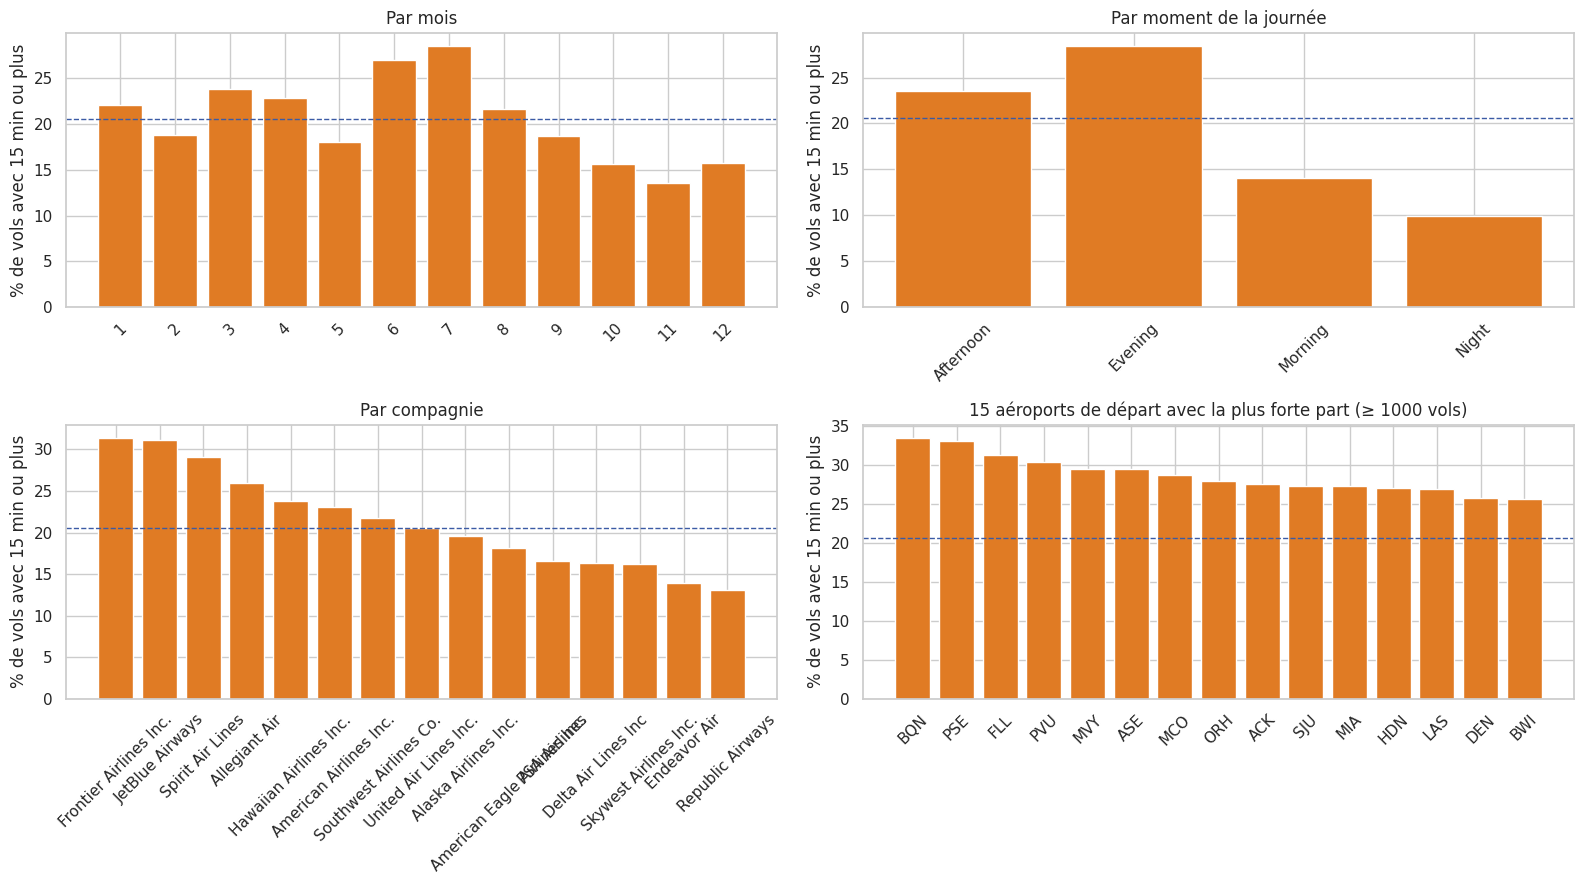

Mois avec la plus forte part de vols en retard (≥ 15 min) : 7 (28.6 %)
Compagnie avec la plus forte part de vols en retard : Frontier Airlines Inc. (31.4 %)
Aéroport avec la plus forte part de vols en retard : BQN (33.5 %)


In [11]:
TAUX_GLOBAL = (vols[C["cible"]] >= 15).mean() * 100

def part15(col, titre, ax, ordre=None, top=None, min_vols=0):
    g = vols.groupby(col, observed=True)[C["cible"]].agg(pct=lambda s: (s >= 15).mean() * 100, count="size")
    g = g[g["count"] >= min_vols]
    if top:
        g = g.sort_values("pct", ascending=False).head(top)
    elif ordre is not None:
        g = g.reindex([o for o in ordre if o in g.index])
    ax.bar(g.index.astype(str), g["pct"], color=ORANGE)
    ax.axhline(TAUX_GLOBAL, color=BLEU, ls="--", lw=1)
    ax.set(title=titre, ylabel="% de vols avec 15 min ou plus")
    ax.tick_params(axis="x", rotation=45)
    return g

fig, ax = plt.subplots(2, 2, figsize=(16, 9))
p_mois = part15("mois", "Par mois", ax[0, 0], ordre=range(1, 13))
if "tranche" in vols:
    part15("tranche", "Par moment de la journée", ax[0, 1])
p_cie = part15(C["compagnie"], "Par compagnie", ax[1, 0], top=30)
p_aer = part15(C["dep"], f"15 aéroports de départ avec la plus forte part (≥ {MIN_VOLS} vols)", ax[1, 1], top=15, min_vols=MIN_VOLS)
sauver("02b_part_vols_en_retard")
print("Mois avec la plus forte part de vols en retard (≥ 15 min)", ":", f"{int(p_mois['pct'].idxmax())} ({p_mois['pct'].max():.1f} %)")
print("Compagnie avec la plus forte part de vols en retard", ":", f"{p_cie['pct'].idxmax()} ({p_cie['pct'].max():.1f} %)")
print("Aéroport avec la plus forte part de vols en retard", ":", f"{p_aer['pct'].idxmax()} ({p_aer['pct'].max():.1f} %)")

## 7. Jointure de la météo (aéroport + date)

La météo est quotidienne. On l'ajoute pour l'aéroport de **départ** et pour celui d'**arrivée**.

> Limite à noter : c'est la météo **observée** le jour du vol. En situation réelle, on utiliserait une **prévision** météo.

In [12]:
VARS_METEO, METEO_COLS = [], []
if F_METEO:
    meteo = pd.read_csv(F_METEO, low_memory=False)
    print(meteo.shape, list(meteo.columns))
    display(meteo.head())
    m_aero = trouver(meteo, "airport_id", "airport", "iata", "iata_code", "code", "station")
    m_date = trouver(meteo, "time", "date", "day")
    print("Aéroport :", m_aero, "| Date :", m_date)
    VARS_METEO = [c for c in meteo.columns if c not in (m_aero, m_date) and pd.api.types.is_numeric_dtype(meteo[c])]
    print("Variables météo :", VARS_METEO)
    display((meteo[VARS_METEO].isna().mean() * 100).round(1).to_frame("manquantes_% (fichier météo)"))

    meteo["_date"] = pd.to_datetime(meteo[m_date], errors="coerce").dt.normalize()
    meteo[m_aero] = meteo[m_aero].astype(str)
    m = meteo[[m_aero, "_date"] + VARS_METEO].drop_duplicates([m_aero, "_date"])
    m[VARS_METEO] = m[VARS_METEO].astype("float32")
    for cote, col_vols in [("dep", C["dep"]), ("arr", C["arr"])]:
        if col_vols is None:
            continue
        mm = m.rename(columns={m_aero: "_aero", **{v: f"{v}_{cote}" for v in VARS_METEO}})
        vols["_aero"] = vols[col_vols].astype(str)
        vols = vols.merge(mm, on=["_aero", "_date"], how="left")
        METEO_COLS += [f"{v}_{cote}" for v in VARS_METEO]
    vols.drop(columns="_aero", inplace=True)
    couverture = vols[f"{VARS_METEO[0]}_dep"].notna().mean() * 100
    print("Vols avec météo de départ trouvée", ":", f"{couverture:.1f} %")
    print(f"Vols avec météo au départ : {couverture:.1f} %")
    if couverture < 50:
        print("ATTENTION : jointure faible. Les codes d'aéroport du fichier météo ne correspondent peut-être pas à ceux des vols.")
else:
    print("Pas de fichier météo trouvé.")

(132860, 10) ['time', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'pres', 'airport_id']


,time,tavg,tmin,tmax,prcp,snow,wdir,wspd,pres,airport_id
0,2023-01-01,8.1,2.2,11.7,0.0,0.0,278.0,9.7,1013.8,ABE
1,2023-01-02,5.4,0.0,11.7,0.0,0.0,353.0,3.6,1019.6,ABE
2,2023-01-03,8.4,7.2,9.4,15.2,0.0,50.0,5.0,1013.9,ABE
3,2023-01-04,11.1,6.7,17.2,0.0,0.0,302.0,4.7,1009.8,ABE
4,2023-01-05,12.7,6.7,14.4,7.9,0.0,292.0,7.2,1013.0,ABE


Aéroport : airport_id | Date : time
Variables météo : ['tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'pres']


,manquantes_% (fichier météo)
tavg,0.0
tmin,0.0
tmax,0.0
prcp,0.0
snow,0.0
wdir,0.0
wspd,0.0
pres,0.0


Vols avec météo de départ trouvée : 100.0 %
Vols avec météo au départ : 100.0 %


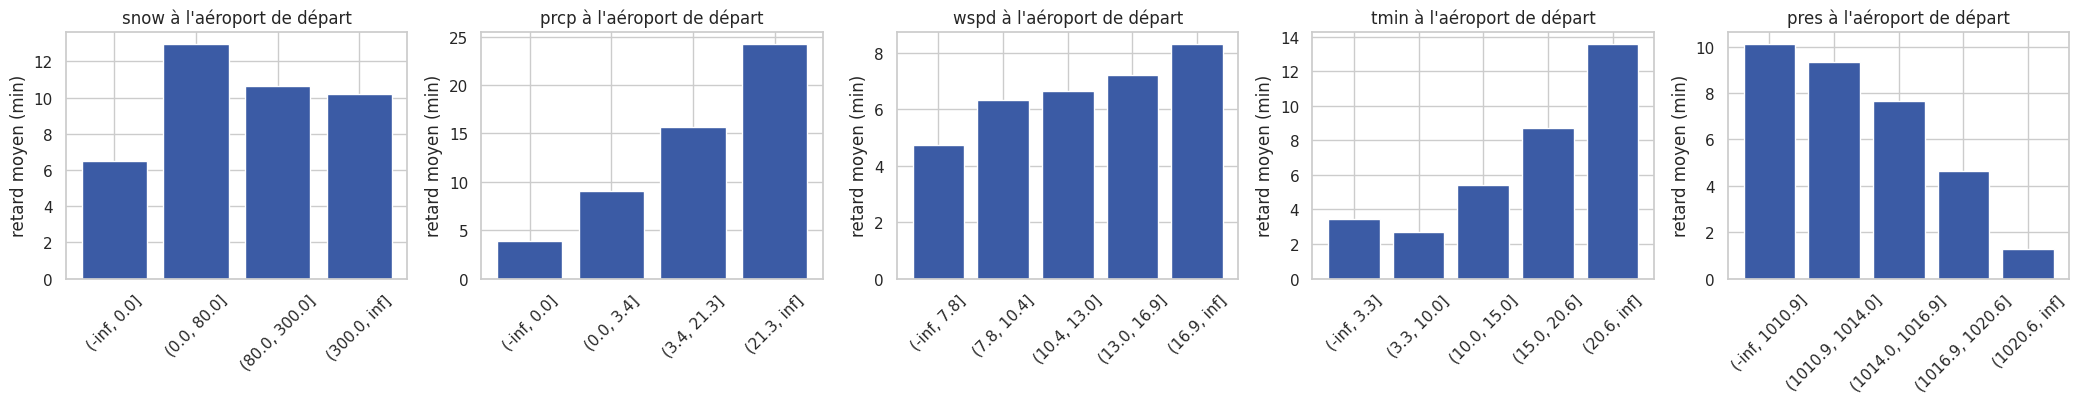

In [13]:
def classes(s):
    s = s.astype(float)
    pos = s[s > 0]
    if (s.fillna(0) == 0).mean() > 0.4 and len(pos):
        bornes = np.r_[-np.inf, 0, np.nanquantile(pos, [.5, .9]), np.inf]
    else:
        bornes = np.r_[-np.inf, np.nanquantile(s, [.2, .4, .6, .8]), np.inf]
    return pd.cut(s, np.unique(bornes))

a_tracer = [v for v in ["snow", "prcp", "wspd", "tmin", "pres"] if f"{v}_dep" in vols] or VARS_METEO[:4]
if a_tracer:
    fig, ax = plt.subplots(1, len(a_tracer), figsize=(4.2 * len(a_tracer), 4.2))
    ax = np.atleast_1d(ax)
    for a, v in zip(ax, a_tracer):
        g = vols.groupby(classes(vols[f"{v}_dep"]), observed=True)[C["cible"]].mean()
        a.bar(g.index.astype(str), g.values, color=BLEU)
        a.set(title=f"{v} à l'aéroport de départ", ylabel="retard moyen (min)")
        a.tick_params(axis="x", rotation=45)
    sauver("04_retard_selon_meteo")

## 8. Corrélations

- **Pearson** mesure une relation linéaire ; **Spearman** mesure une relation qui monte ou descend (plus robuste aux valeurs extrêmes, utile ici car la cible est très asymétrique).
- Les variables de **fuite de données** sont montrées **en rouge** pour illustrer pourquoi on les exclut : elles sont très corrélées à la cible, mais inconnues avant le départ.

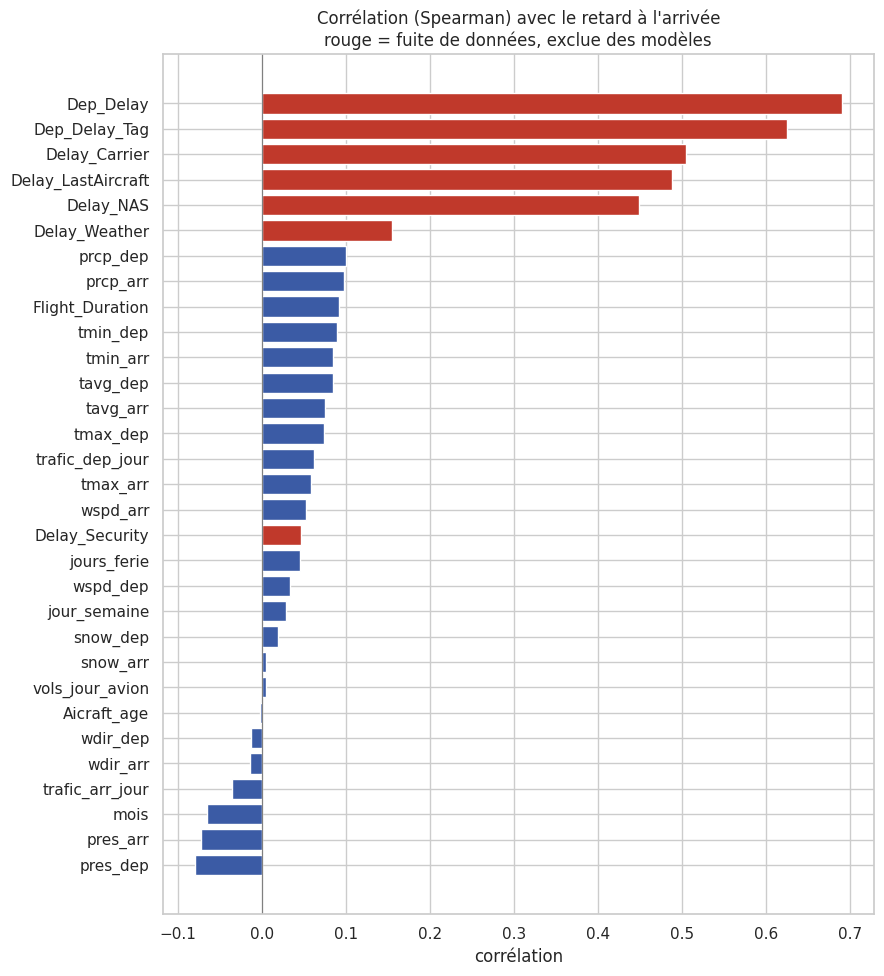

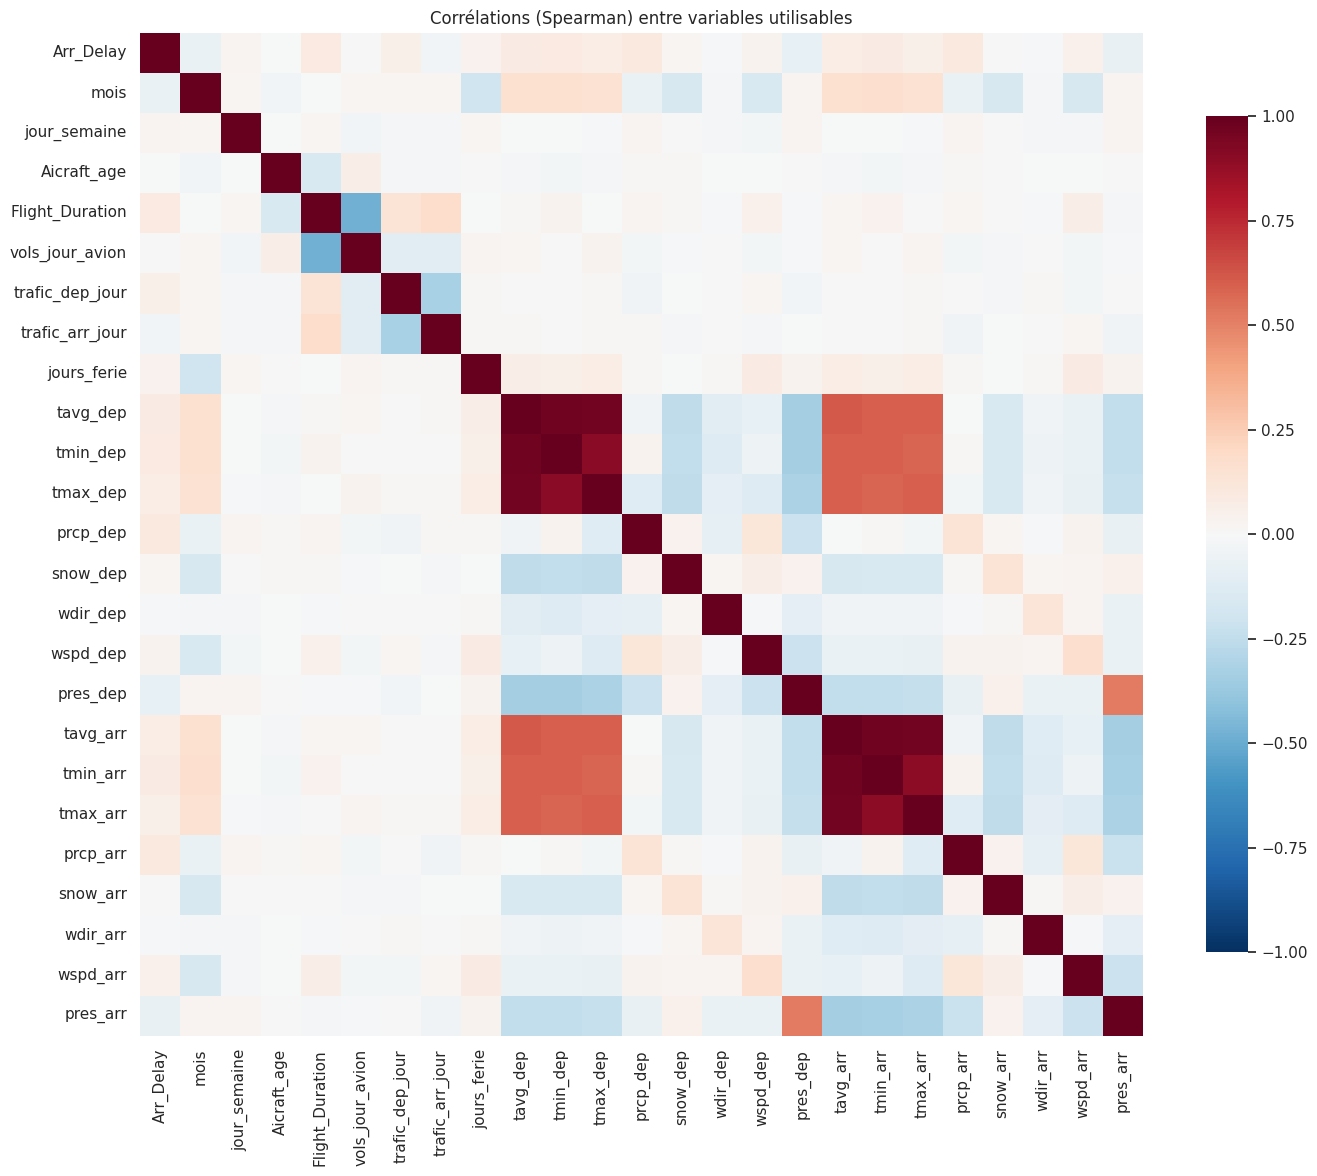

,Spearman,Pearson,utilisable
Dep_Delay,0.690,0.972,non (fuite)
Dep_Delay_Tag,0.625,0.387,non (fuite)
Delay_Carrier,0.504,0.703,non (fuite)
Delay_LastAircraft,0.488,0.606,non (fuite)
Delay_NAS,0.449,0.321,non (fuite)
Delay_Weather,0.154,0.288,non (fuite)
prcp_dep,0.100,0.073,oui
prcp_arr,0.097,0.062,oui
Flight_Duration,0.091,0.053,oui
tmin_dep,0.089,0.055,oui


Corrélations (Spearman) les plus fortes, variables utilisables : prcp_dep (+0.10), prcp_arr (+0.10), Flight_Duration (+0.09), tmin_dep (+0.09), tmin_arr (+0.08)
Corrélation du retard au départ avec la cible (fuite) : +0.69


In [14]:
CANDIDATES = ["mois", "jour_semaine", "heure_dep", C["age"], C["duree"], C["distance"],
              "vols_jour_avion", "rang_vol_jour", "trafic_dep_jour", "trafic_arr_jour", "jours_ferie"] + METEO_COLS
NUM_COLS = [c for c in dict.fromkeys(CANDIDATES) if c and c in vols and pd.api.types.is_numeric_dtype(vols[c])]
FUITE_NUM = [c for c in FUITE if pd.api.types.is_numeric_dtype(vols[c])]

ech = vols.sample(min(300_000, len(vols)), random_state=GRAINE)
corr_s = ech[[C["cible"]] + NUM_COLS + FUITE_NUM].corr(method="spearman")[C["cible"]].drop(C["cible"]).sort_values()
corr_p = ech[[C["cible"]] + NUM_COLS + FUITE_NUM].corr(method="pearson")[C["cible"]].drop(C["cible"])

fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(corr_s))))
couleurs = [ROUGE if c in FUITE_NUM else BLEU for c in corr_s.index]
ax.barh(corr_s.index, corr_s.values, color=couleurs)
ax.axvline(0, color="grey", lw=0.8)
ax.set(title="Corrélation (Spearman) avec le retard à l'arrivée\nrouge = fuite de données, exclue des modèles", xlabel="corrélation")
sauver("05_correlation_avec_cible")

if len(NUM_COLS) > 1:
    plt.figure(figsize=(min(1 + 0.55 * len(NUM_COLS), 16), min(1 + 0.5 * len(NUM_COLS), 14)))
    sns.heatmap(ech[[C["cible"]] + NUM_COLS].corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                annot=len(NUM_COLS) <= 14, fmt=".2f", square=True, cbar_kws={"shrink": .7})
    plt.title("Corrélations (Spearman) entre variables utilisables")
    sauver("06_matrice_correlation")

tab = pd.DataFrame({"Spearman": corr_s, "Pearson": corr_p}).round(3)
tab["utilisable"] = np.where(tab.index.isin(FUITE_NUM), "non (fuite)", "oui")
display(tab.sort_values("Spearman", key=abs, ascending=False))
utiles = tab[tab["utilisable"] == "oui"]["Spearman"]
print("Corrélations (Spearman) les plus fortes, variables utilisables", ":", ", ".join(
    f"{i} ({v:+.2f})" for i, v in utiles.reindex(utiles.abs().sort_values(ascending=False).index).head(5).items()))
if C["dep_delay"] in tab.index:
    print("Corrélation du retard au départ avec la cible (fuite)", ":", f"{tab.loc[C['dep_delay'], 'Spearman']:+.2f}")

## 9. Âge de l'avion, effet domino, trafic et jours fériés

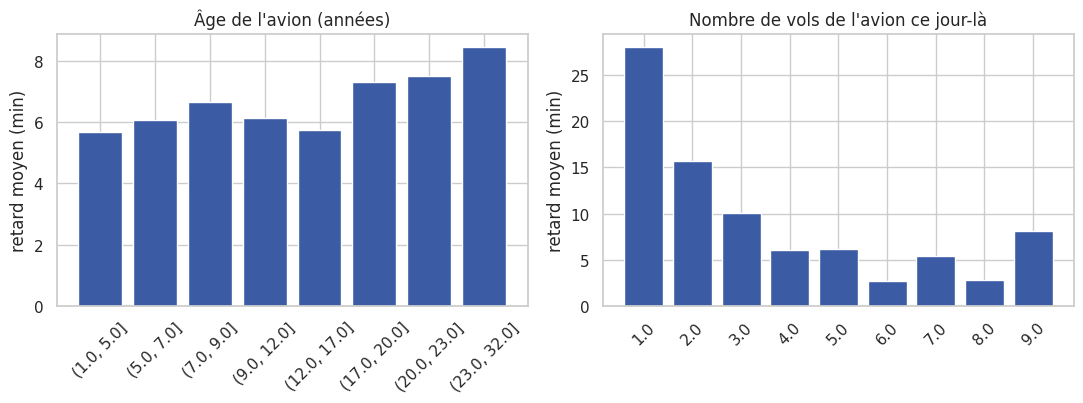

In [15]:
graphs = [g for g in [C["age"], "vols_jour_avion", "rang_vol_jour"] if g and g in vols]
if graphs:
    fig, ax = plt.subplots(1, len(graphs), figsize=(5.5 * len(graphs), 4.2))
    ax = np.atleast_1d(ax)
    for a, g in zip(ax, graphs):
        s = vols[g].clip(upper=vols[g].quantile(.99))
        grp = vols.groupby(pd.cut(s, np.unique(np.nanquantile(s, np.linspace(0, 1, 9)))) if g == C["age"] else s.round(),
                           observed=True)[C["cible"]].agg(["mean", "count"])
        grp = grp[grp["count"] >= MIN_VOLS / 10]
        a.bar(grp.index.astype(str), grp["mean"], color=BLEU)
        a.set(title={C["age"]: "Âge de l'avion (années)", "vols_jour_avion": "Nombre de vols de l'avion ce jour-là",
                     "rang_vol_jour": "Rang du vol dans la journée de l'avion"}.get(g, g), ylabel="retard moyen (min)")
        a.tick_params(axis="x", rotation=45)
    sauver("07_age_et_effet_domino")

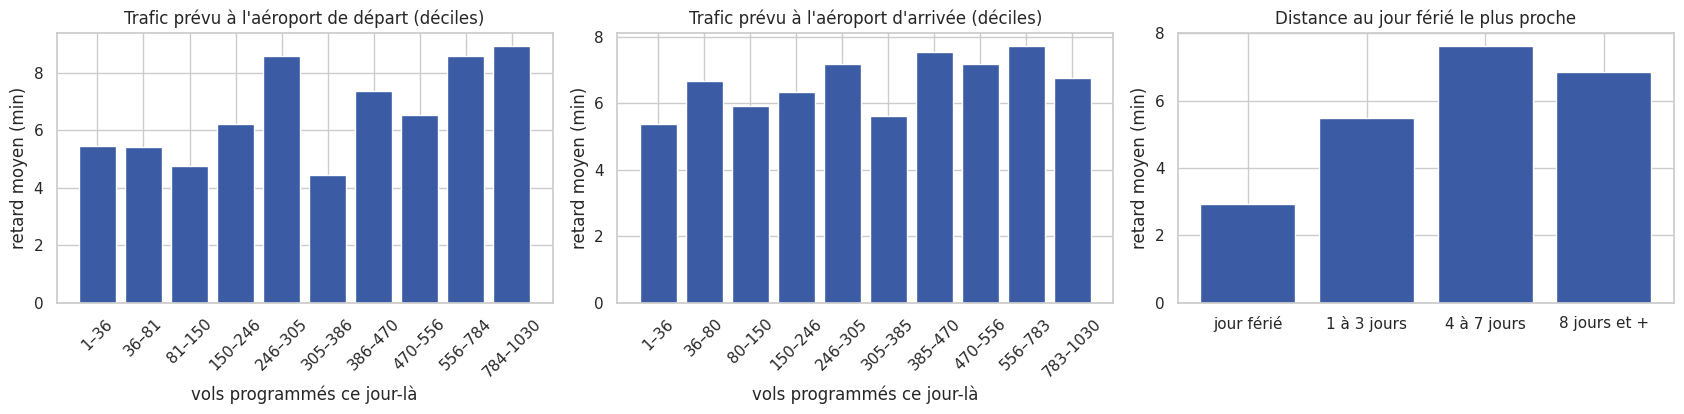

Retard moyen : 10 % des jours les plus chargés vs les moins chargés (départ) : 8.9 vs 5.5 min
Retard moyen : à 3 jours ou moins d'un jour férié vs le reste : 5.1 vs 7.0 min


,moyenne,pct
jours_ferie,,
jour férié,2.9,17.2
1 à 3 jours,5.5,19.9
4 à 7 jours,7.6,21.0
8 jours et +,6.8,20.8


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
graphes = [("trafic_dep_jour", "Trafic prévu à l'aéroport de départ (déciles)"),
           ("trafic_arr_jour", "Trafic prévu à l'aéroport d'arrivée (déciles)")]
for a, (col, titre) in zip(ax[:2], graphes):
    classes_trafic = pd.qcut(vols[col], 10, duplicates="drop")
    g = vols.groupby(classes_trafic, observed=True)[C["cible"]].agg(moyenne="mean", pct=lambda s: (s >= 15).mean() * 100)
    a.bar(range(len(g)), g["moyenne"], color=BLEU)
    a.set_xticks(range(len(g)), [f"{iv.left:.0f}–{iv.right:.0f}" for iv in g.index], rotation=45)
    a.set(title=titre, xlabel="vols programmés ce jour-là", ylabel="retard moyen (min)")
cl = pd.cut(vols["jours_ferie"], [-0.5, 0.5, 3.5, 7.5, 15.5], labels=["jour férié", "1 à 3 jours", "4 à 7 jours", "8 jours et +"])
g = vols.groupby(cl, observed=True)[C["cible"]].agg(moyenne="mean", pct=lambda s: (s >= 15).mean() * 100)
ax[2].bar(g.index.astype(str), g["moyenne"], color=BLEU)
ax[2].set(title="Distance au jour férié le plus proche", ylabel="retard moyen (min)")
sauver("07b_trafic_et_jours_feries")

t = vols["trafic_dep_jour"]
haut, bas = vols.loc[t >= t.quantile(.9), C["cible"]], vols.loc[t <= t.quantile(.1), C["cible"]]
print("Retard moyen : 10 % des jours les plus chargés vs les moins chargés (départ)", ":", f"{haut.mean():.1f} vs {bas.mean():.1f} min")
proche = vols["jours_ferie"] <= 3
print("Retard moyen : à 3 jours ou moins d'un jour férié vs le reste", ":", (
    f"{vols.loc[proche, C['cible']].mean():.1f} vs {vols.loc[~proche, C['cible']].mean():.1f} min"))
display(g.round(1))

## 10. Valeurs inhabituelles

On repère les valeurs extrêmes ou impossibles. Les retards très longs sont **réels** (ce ne sont pas des erreurs), mais ils pèsent beaucoup dans la RMSE.

,nombre de vols,% des vols
Retards au-dessus du seuil IQR (45 min),607450,9.008
Retards de plus de 5 heures (300 min),30395,0.451
Retards de plus de 24 heures (1440 min),537,0.008
Arrivées avec plus de 60 min d'avance,1453,0.022
Vols dont le départ = l'arrivée,0,0.000
Âge d'avion négatif ou > 60 ans,0,0.000
Dates illisibles,0,0.000
Météo : température min > max,4,0.000
Météo : prcp_dep négatif,0,0.000
Météo : snow_dep négatif,0,0.000


Retards au-dessus du seuil IQR : 9.0 % des vols (seuil 45 min)
Retards de plus de 5 heures : 30,395 vols


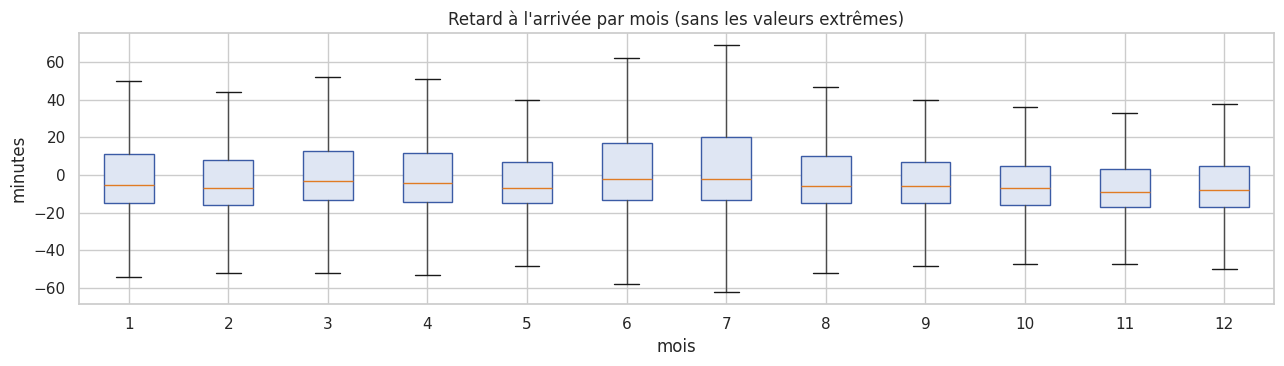

In [17]:
y = vols[C["cible"]].dropna()
q1, q3 = y.quantile([.25, .75])
seuil_haut = q3 + 1.5 * (q3 - q1)
controles = {
    f"Retards au-dessus du seuil IQR ({seuil_haut:.0f} min)": int((y > seuil_haut).sum()),
    "Retards de plus de 5 heures (300 min)": int((y > 300).sum()),
    "Retards de plus de 24 heures (1440 min)": int((y > 1440).sum()),
    "Arrivées avec plus de 60 min d'avance": int((y < -60).sum()),
}
if C["dep"] and C["arr"]:
    controles["Vols dont le départ = l'arrivée"] = int((vols[C["dep"]].astype(str) == vols[C["arr"]].astype(str)).sum())
if C["age"]:
    controles["Âge d'avion négatif ou > 60 ans"] = int(((vols[C["age"]] < 0) | (vols[C["age"]] > 60)).sum())
controles["Dates illisibles"] = int(vols["_date"].isna().sum())
if "tmin_dep" in vols and "tmax_dep" in vols:
    controles["Météo : température min > max"] = int((vols["tmin_dep"] > vols["tmax_dep"]).sum())
for v in ["prcp_dep", "snow_dep", "wspd_dep"]:
    if v in vols:
        controles[f"Météo : {v} négatif"] = int((vols[v] < 0).sum())

tab_inhab = pd.DataFrame({"nombre de vols": controles})
tab_inhab["% des vols"] = (tab_inhab["nombre de vols"] / len(vols) * 100).round(3)
display(tab_inhab)
print("Retards au-dessus du seuil IQR", ":", f"{(y > seuil_haut).mean() * 100:.1f} % des vols (seuil {seuil_haut:.0f} min)")
print("Retards de plus de 5 heures", ":", f"{int((y > 300).sum()):,} vols")

fig, ax = plt.subplots(figsize=(13, 4))
vols.boxplot(column=C["cible"], by="mois", ax=ax, showfliers=False, patch_artist=True,
             boxprops=dict(facecolor="#dfe6f3", color=BLEU), medianprops=dict(color=ORANGE))
ax.set(title="Retard à l'arrivée par mois (sans les valeurs extrêmes)", xlabel="mois", ylabel="minutes")
plt.suptitle("")
sauver("08_boites_par_mois")

## 11. Pistes d'innovation

La prédiction des retards est un sujet déjà très traité. Pour se démarquer, nous ajoutons deux volets originaux, explorés ici sans modèle (les modèles viendront au Jalon 2) :

1. **Transfert vers le Canada :** les aéroports du **nord** des États-Unis ont des hivers proches du Canada. Si leurs retards se comportent différemment de ceux du **sud**, un modèle entraîné sur un climat doux pourrait mal se transférer : c'est ce que nous testerons au Jalon 2.
2. **Prédiction par intervalle :** si les retards d'une même route varient beaucoup, un seul chiffre ne suffit pas. Il faut donner un **intervalle** (par exemple « entre 5 et 45 minutes »).

,vols,retard moyen (min),retard médian (min),% ≥ 15 min,retard moyen en hiver (min),retard moyen le reste de l'année (min),% de jours avec neige
zone,,,,,,,
Nord (climat canadien),1432916,6.0,-6.0,20.7,4.1,6.5,9.6
Sud,2413239,8.3,-4.0,22.0,5.3,9.3,0.0


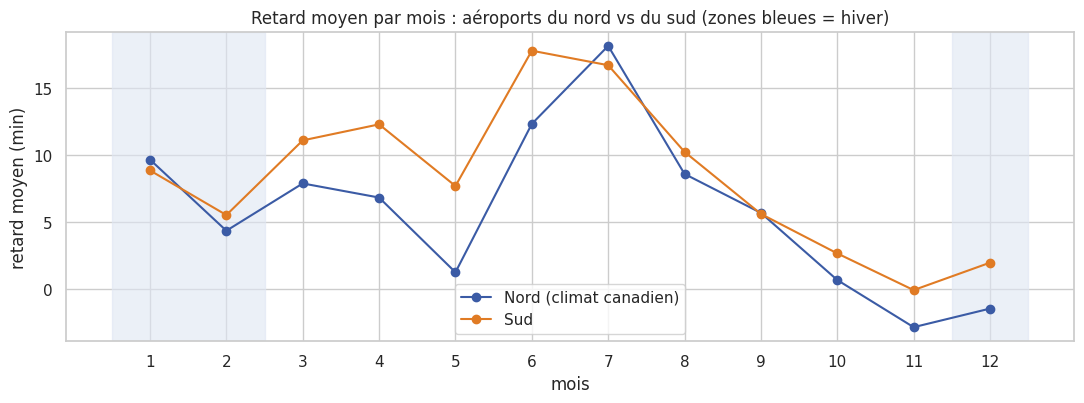

Innovation – retard moyen en hiver (nord / sud) : 4.1 / 5.3 min
Innovation – % de vols avec neige au départ (nord / sud) : 9.6 % / 0.0 %


In [18]:
NORD = ["ORD", "MDW", "MSP", "DTW", "BOS", "BUF", "CLE", "MKE", "PIT", "ROC", "SYR", "ALB", "BDL", "PVD", "PWM",
        "BTV", "MHT", "DEN", "SLC", "GRR", "MSN", "DSM", "OMA", "FAR", "FSD", "ANC"]
SUD = ["ATL", "DFW", "DAL", "IAH", "HOU", "MIA", "FLL", "MCO", "TPA", "PHX", "LAS", "LAX", "SAN", "SAT", "AUS",
       "MSY", "JAX", "RSW", "PBI", "HNL", "ONT", "SNA", "BUR", "ELP", "TUS", "OGG"]
dep_txt = vols[C["dep"]].astype(str)
zone = pd.Series(np.where(dep_txt.isin(NORD), "Nord (climat canadien)", np.where(dep_txt.isin(SUD), "Sud", None)), index=vols.index)

if zone.notna().sum() > 1000:
    z = vols.assign(zone=zone).dropna(subset=["zone"])
    hiver = z["mois"].isin([12, 1, 2])
    agg = {"vols": (C["cible"], "size"), "retard moyen (min)": (C["cible"], "mean"),
           "retard médian (min)": (C["cible"], "median"),
           "% ≥ 15 min": (C["cible"], lambda s: (s >= 15).mean() * 100)}
    comp = z.groupby("zone").agg(**agg)
    comp["retard moyen en hiver (min)"] = z[hiver].groupby("zone")[C["cible"]].mean()
    comp["retard moyen le reste de l'année (min)"] = z[~hiver].groupby("zone")[C["cible"]].mean()
    if "snow_dep" in z:
        comp["% de jours avec neige"] = z.groupby("zone")["snow_dep"].apply(lambda s: (s > 0).mean() * 100)
    display(comp.round(1))

    fig, ax = plt.subplots(figsize=(11, 4.2))
    for nom, couleur in [("Nord (climat canadien)", BLEU), ("Sud", ORANGE)]:
        m = z[z["zone"] == nom].groupby("mois")[C["cible"]].mean()
        ax.plot(m.index, m.values, "o-", color=couleur, label=nom)
    ax.axvspan(0.5, 2.5, color="#dfe6f3", alpha=.6); ax.axvspan(11.5, 12.5, color="#dfe6f3", alpha=.6)
    ax.set(title="Retard moyen par mois : aéroports du nord vs du sud (zones bleues = hiver)",
           xlabel="mois", ylabel="retard moyen (min)", xticks=range(1, 13))
    ax.legend()
    sauver("09_innovation_nord_vs_sud")
    n, s = comp.loc["Nord (climat canadien)"], comp.loc["Sud"]
    print("Innovation – retard moyen en hiver (nord / sud)", ":", f"{n['retard moyen en hiver (min)']:.1f} / {s['retard moyen en hiver (min)']:.1f} min")
    if "% de jours avec neige" in comp:
        print("Innovation – % de vols avec neige au départ (nord / sud)", ":", f"{n['% de jours avec neige']:.1f} % / {s['% de jours avec neige']:.1f} %")
else:
    print("Codes d'aéroports non reconnus (ce ne sont peut-être pas des codes IATA) : comparaison nord/sud ignorée.")

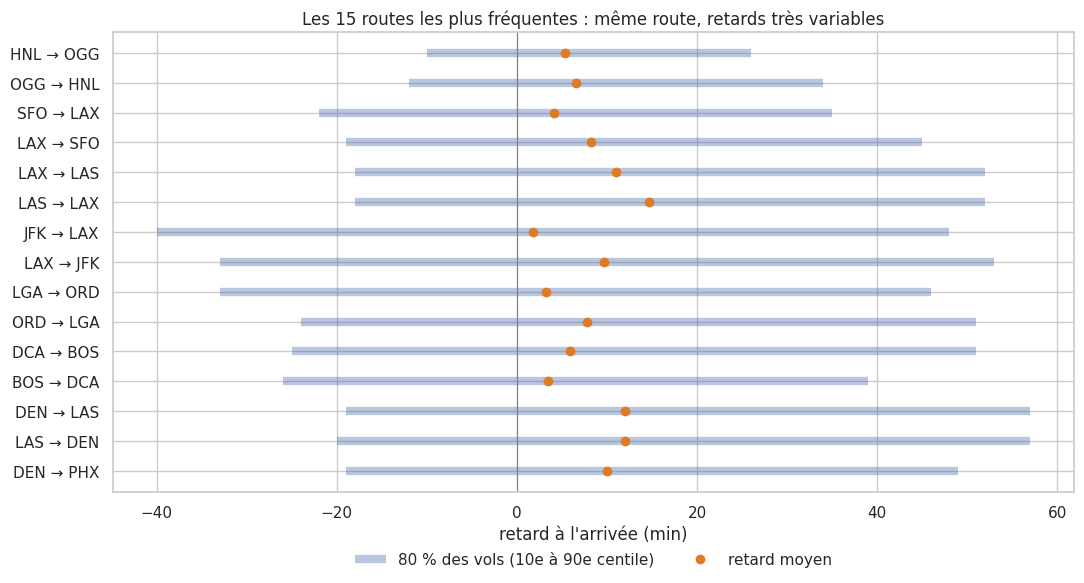

,vols,moyenne,p10,p90,largeur 10–90 % (min)
HNL → OGG,12458,5.3,-10.0,26.0,36.0
OGG → HNL,12428,6.6,-12.0,34.0,46.0
SFO → LAX,11538,4.1,-22.0,35.0,57.0
LAX → SFO,11533,8.3,-19.0,45.0,64.0
LAX → LAS,10396,11.0,-18.0,52.0,70.0
LAS → LAX,10379,14.7,-18.0,52.0,70.0
JFK → LAX,9950,1.8,-40.0,48.0,88.0
LAX → JFK,9929,9.6,-33.0,53.0,86.0
LGA → ORD,9635,3.2,-33.0,46.0,79.0
ORD → LGA,9619,7.8,-24.0,51.0,75.0


Innovation – largeur médiane de l'intervalle 10–90 % par route : 59 min (sur 5,329 routes)


In [19]:
# Dispersion des retards sur une même route : justifie la prédiction par intervalle
route = vols[C["dep"]].astype(str) + " → " + vols[C["arr"]].astype(str)
stats = vols.groupby(route)[C["cible"]].agg(vols="size", moyenne="mean",
                                            p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9))
stats = stats[stats["vols"] >= max(30, MIN_VOLS // 10)]
stats["largeur 10–90 % (min)"] = stats["p90"] - stats["p10"]
top = stats.sort_values("vols", ascending=False).head(15)[::-1]

fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(top.index, top["p10"], top["p90"], color=BLEU, lw=6, alpha=.35, label="80 % des vols (10e à 90e centile)")
ax.plot(top["moyenne"], top.index, "o", color=ORANGE, label="retard moyen")
ax.axvline(0, color="grey", lw=.8)
ax.set(title="Les 15 routes les plus fréquentes : même route, retards très variables", xlabel="retard à l'arrivée (min)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
sauver("10_innovation_dispersion_par_route")
display(top[::-1].round(1))
print("Innovation – largeur médiane de l'intervalle 10–90 % par route", ":", f"{stats['largeur 10–90 % (min)'].median():.0f} min (sur {len(stats):,} routes)")

## 12. Dictionnaire de données

Le dictionnaire est généré automatiquement : nom réel de chaque colonne, type, description, exemple, valeurs manquantes et rôle. Il est enregistré dans `dictionnaire_donnees.csv`, qui s'ouvre dans Excel.

> Vérifiez les lignes marquées « à vérifier » et « à compléter ».

In [20]:
DESCRIPTIONS = {
    "flightdate": "Date du vol", "fldate": "Date du vol", "dayofweek": "Jour de la semaine (1 = lundi)",
    "airline": "Compagnie aérienne", "carrier": "Compagnie aérienne", "tailnumber": "Immatriculation de l'avion",
    "depairport": "Aéroport de départ (code)", "origin": "Aéroport de départ (code)",
    "depcityname": "Ville de départ", "deptimelabel": "Moment de la journée du départ",
    "depdelay": "Retard au départ (minutes)", "depdelaytag": "Indicateur de retard au départ",
    "depdelaytype": "Catégorie du retard au départ", "arrairport": "Aéroport d'arrivée (code)",
    "dest": "Aéroport d'arrivée (code)", "arrcityname": "Ville d'arrivée",
    "arrdelay": "Retard à l'arrivée (minutes) – variable cible", "arrdelaytype": "Catégorie du retard à l'arrivée",
    "flightduration": "Durée du vol (minutes)", "distancetype": "Catégorie de distance du vol",
    "distance": "Distance du vol (milles)", "delaycarrier": "Minutes de retard dues à la compagnie",
    "delayweather": "Minutes de retard dues à la météo", "delaynas": "Minutes de retard dues au système aérien",
    "delaysecurity": "Minutes de retard dues à la sécurité", "delaylastaircraft": "Minutes de retard dues à l'avion précédent",
    "manufacturer": "Constructeur de l'avion", "model": "Modèle de l'avion", "aicraftage": "Âge de l'avion (années)",
    "aircraftage": "Âge de l'avion (années)",
    "mois": "Mois du vol (créée)", "joursemaine": "Jour de la semaine, 1 = lundi (créée)",
    "heuredep": "Heure de départ prévue (créée)", "tranche": "Moment de la journée (créée)",
    "volsjouravion": "Nombre de vols du même avion ce jour-là (créée)",
    "rangvoljour": "Rang du vol dans la journée de l'avion (créée)",
    "traficdepjour": "Nombre de vols programmés ce jour-là à l'aéroport de départ (créée)",
    "traficarrjour": "Nombre de vols programmés ce jour-là à l'aéroport d'arrivée (créée)",
    "joursferie": "Nombre de jours jusqu'au jour férié américain le plus proche, plafonné à 15 (créée)",
}
METEO_DESC = {"tavg": "Température moyenne (°C)", "tmin": "Température minimale (°C)", "tmax": "Température maximale (°C)",
              "prcp": "Précipitations (mm)", "snow": "Neige (mm)", "wdir": "Direction du vent (degrés)",
              "wspd": "Vitesse du vent (km/h)", "pres": "Pression (hPa)"}
for v in VARS_METEO:
    for cote, lieu in [("dep", "à l'aéroport de départ"), ("arr", "à l'aéroport d'arrivée")]:
        DESCRIPTIONS[norm(f"{v}_{cote}")] = f"{METEO_DESC.get(v, v)} {lieu} (jointe)"

REDONDANTES = [c for c in vols.columns if re.search(r"cityname|city_name", c, re.I)]
CAUSES = [c for c in vols.columns if re.search(r"^delay_|_delay$", c, re.I) and c not in (C["cible"], C["dep_delay"])]

def role(c):
    if c == C["cible"]:
        return "Oui (cible)"
    if c in CAUSES:
        return "Analyse seulement (fuite)"
    if c in FUITE:
        return "Non (fuite de données)"
    if c == C["avion"]:
        return "Non (sert à créer vols_jour_avion)"
    if c in REDONDANTES:
        return "Non (redondant avec l'aéroport)"
    if c == C["date"]:
        return "Oui (via mois et jour_semaine)"
    if c in (C["duree"], C["heure"]):
        return "À vérifier (prévue ou réelle ?)"
    return "Oui"

def type_fr(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return "Date"
    if pd.api.types.is_numeric_dtype(s):
        return "Binaire" if s.dropna().isin([0, 1]).all() and s.nunique() <= 2 else "Numérique"
    return "Date" if s.name == C["date"] else "Catégorielle"

colonnes = [c for c in vols.columns if not c.startswith("_")]
dico = pd.DataFrame({
    "Variable": colonnes,
    "Type": [type_fr(vols[c]) for c in colonnes],
    "Description": [DESCRIPTIONS.get(norm(c), "à compléter") for c in colonnes],
    "Exemple": [(round(float(v), 2) if isinstance(v, (float, np.floating)) else v) for v in (vols[c].dropna().iloc[0] if vols[c].notna().any() else "" for c in colonnes)],
    "Manquantes (%)": [round(vols[c].isna().mean() * 100, 2) for c in colonnes],
    "Valeurs distinctes": [int(vols[c].nunique()) for c in colonnes],
    "Utilisée ?": [role(c) for c in colonnes],
})
dico.to_csv("dictionnaire_donnees.csv", index=False, encoding="utf-8-sig")
display(dico)
print("Variables dans le dictionnaire", ":", f"{len(dico)} (dont {int((dico['Utilisée ?'].str.startswith('Oui')).sum())} utilisables pour prédire)")

,Variable,Type,Description,Exemple,Manquantes (%),Valeurs distinctes,Utilisée ?
0,FlightDate,Date,Date du vol,2023-01-02,0.0,365,Oui (via mois et jour_semaine)
1,Day_Of_Week,Numérique,Jour de la semaine (1 = lundi),1,0.0,7,Oui
2,Airline,Catégorielle,Compagnie aérienne,Endeavor Air,0.0,15,Oui
3,Tail_Number,Catégorielle,Immatriculation de l'avion,N605LR,0.0,5963,Non (sert à créer vols_jour_avion)
4,Dep_Airport,Catégorielle,Aéroport de départ (code),BDL,0.0,350,Oui
5,Dep_CityName,Catégorielle,Ville de départ,"Hartford, CT",0.0,344,Non (redondant avec l'aéroport)
6,DepTime_label,Catégorielle,Moment de la journée du départ,Morning,0.0,4,À vérifier (prévue ou réelle ?)
7,Dep_Delay,Numérique,Retard au départ (minutes),-3,0.0,1854,Non (fuite de données)
8,Dep_Delay_Tag,Binaire,Indicateur de retard au départ,0,0.0,2,Non (fuite de données)
9,Dep_Delay_Type,Catégorielle,Catégorie du retard au départ,Low <5min,0.0,3,Non (fuite de données)


Variables dans le dictionnaire : 47 (dont 33 utilisables pour prédire)


## 13. Préparation des données (partie 1) : nettoyage de base

Chaque étape est notée dans un **journal de nettoyage**, utile pour le journal de projet. Le fichier préparé ne garde que les colonnes utiles à la modélisation ; les causes de retard restent dans le fichier d'origine pour l'analyse.

In [21]:
journal = []
def etape(nom, avant, apres, detail=""):
    journal.append({"étape": nom, "vols avant": avant, "vols après": apres, "retirés": avant - apres, "détail": detail})

prep = vols
n = len(prep); prep = prep.drop_duplicates(subset=[c for c in prep.columns if not c.startswith("_")])
etape("Suppression des doublons", n, len(prep))
n = len(prep); prep = prep.dropna(subset=[C["cible"]])
etape("Suppression des vols sans retard à l'arrivée", n, len(prep), "annulés ou déroutés restants")
n = len(prep); prep = prep[prep["_date"].notna()]
etape("Suppression des dates illisibles", n, len(prep))
if C["dep"] and C["arr"]:
    n = len(prep); prep = prep[prep[C["dep"]].astype(str) != prep[C["arr"]].astype(str)]
    etape("Suppression des vols départ = arrivée", n, len(prep))
if C["age"]:
    impossibles = int(((prep[C["age"]] < 0) | (prep[C["age"]] > 60)).sum())
    prep.loc[(prep[C["age"]] < 0) | (prep[C["age"]] > 60), C["age"]] = np.nan
    etape("Âges impossibles remplacés par une valeur manquante", len(prep), len(prep), f"{impossibles} valeurs")

retirer = [c for c in FUITE + REDONDANTES + [C["avion"]] if c and c in prep]
garder = [c for c in prep.columns if c not in retirer and not c.startswith("_")]
prep = prep[garder].copy()
etape("Colonnes retirées (fuite, redondantes, identifiant)", len(prep), len(prep), ", ".join(retirer))

for c in prep.select_dtypes("float64").columns:
    prep[c] = prep[c].astype("float32")
for c in prep.select_dtypes("object").columns:
    prep[c] = prep[c].astype("category")

journal = pd.DataFrame(journal)
display(journal)
print(f"Données préparées : {len(prep):,} vols × {prep.shape[1]} colonnes – {prep.memory_usage(deep=True).sum()/1e9:.2f} Go")
print("Colonnes gardées :", list(prep.columns))

prep.to_parquet("vols_prepares.parquet", index=False)
journal.to_csv("journal_nettoyage.csv", index=False, encoding="utf-8-sig")
print("Vols après nettoyage", ":", f"{len(prep):,} ({(1 - len(prep) / len(vols)) * 100:.2f} % retirés)")
print("Colonnes retirées", ":", ", ".join(retirer))
print("\nFichiers créés : vols_prepares.parquet, journal_nettoyage.csv")

,étape,vols avant,vols après,retirés,détail
0,Suppression des doublons,6743404,6743373,31,
1,Suppression des vols sans retard à l'arrivée,6743373,6743373,0,annulés ou déroutés restants
2,Suppression des dates illisibles,6743373,6743373,0,
3,Suppression des vols départ = arrivée,6743373,6743373,0,
4,Âges impossibles remplacés par une valeur manq...,6743373,6743373,0,0 valeurs
5,"Colonnes retirées (fuite, redondantes, identif...",6743373,6743373,0,"Dep_Delay, Dep_Delay_Tag, Dep_Delay_Type, Arr_..."


Données préparées : 6,743,373 vols × 35 colonnes – 0.94 Go
Colonnes gardées : ['FlightDate', 'Day_Of_Week', 'Airline', 'Dep_Airport', 'DepTime_label', 'Arr_Airport', 'Arr_Delay', 'Flight_Duration', 'Distance_type', 'Manufacturer', 'Model', 'Aicraft_age', 'mois', 'jour_semaine', 'tranche', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']
Vols après nettoyage : 6,743,373 (0.00 % retirés)
Colonnes retirées : Dep_Delay, Dep_Delay_Tag, Dep_Delay_Type, Arr_Delay_Type, Delay_Carrier, Delay_Weather, Delay_NAS, Delay_Security, Delay_LastAircraft, Dep_CityName, Arr_CityName, Tail_Number

Fichiers créés : vols_prepares.parquet, journal_nettoyage.csv


## 14. Fichiers produits

Les graphiques sont regroupés dans `figures_predivol.zip`. **Pensez à sauvegarder** : les fichiers de Colab sont effacés à la fermeture. Copiez `vols_prepares.parquet` dans votre Google Drive pour le Jalon 2.

In [22]:
shutil.make_archive("figures_predivol", "zip", "figures")
try:
    from google.colab import files
    for nom in ["figures_predivol.zip", "dictionnaire_donnees.csv", "journal_nettoyage.csv"]:
        files.download(nom)
except Exception:
    print("Fichiers créés : figures_predivol.zip, dictionnaire_donnees.csv, journal_nettoyage.csv, vols_prepares.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import drive
import os, shutil
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/predivol", exist_ok=True)
shutil.copy("vols_prepares.parquet", "/content/drive/MyDrive/predivol/vols_prepares.parquet")
print("Fichier copié dans Google Drive : MyDrive/predivol/vols_prepares.parquet")

Mounted at /content/drive
Fichier copié dans Google Drive : MyDrive/predivol/vols_prepares.parquet


# Partie 2 – Prétraitement, séparation des données et premiers modèles

In [24]:
# Bibliothèques de modélisation
import os, time, json, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid")
os.makedirs("figures_jalon2", exist_ok=True)
BLEU, ORANGE, GRIS = "#3b5ba5", "#e07b24", "#9aa3b2"

def sauver(nom):
    plt.tight_layout(); plt.savefig(f"figures_jalon2/{nom}.png", dpi=130, bbox_inches="tight"); plt.show()

In [25]:
import gc
for nom in ["vols", "prep", "meteo", "y"]:      # libère la mémoire de la partie 1
    globals().pop(nom, None)
gc.collect()

vols = pd.read_parquet("vols_prepares.parquet")
print(f"{len(vols):,} vols × {vols.shape[1]} colonnes")
print(list(vols.columns))

6,743,373 vols × 35 colonnes
['FlightDate', 'Day_Of_Week', 'Airline', 'Dep_Airport', 'DepTime_label', 'Arr_Airport', 'Arr_Delay', 'Flight_Duration', 'Distance_type', 'Manufacturer', 'Model', 'Aicraft_age', 'mois', 'jour_semaine', 'tranche', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']


## 16. Prétraitement : choix des variables

- **Cible :** `Arr_Delay` (minutes).
- **Variables catégorielles :** compagnie, aéroports, moment de la journée, catégorie de distance, constructeur et modèle d'avion.
- **Variables numériques :** mois, jour de la semaine, âge de l'avion, effet domino, trafic prévu, jours fériés, météo au départ et à l'arrivée.
- **Exclues :** la date (elle sert seulement à séparer les données), `Day_Of_Week` (doublon de `jour_semaine`), `tranche` (doublon de `DepTime_label`) et `Flight_Duration` (probablement la durée réelle, donc une fuite possible).

L'encodage et l'imputation sont faits **dans des pipelines** et appris **sur l'entraînement seulement**, pour éviter toute fuite d'information vers la validation et le test.

In [26]:
# ===== PARAMÈTRES DE LA PARTIE 2 =====
TAILLE_ECHANTILLON = 1_200_000   # nombre total de vols utilisés (entraînement + validation + test)
UTILISER_DUREE = False           # Flight_Duration est probablement la durée RÉELLE : exclue (fuite de données)
SEUIL_GROS_RETARD = 60           # minutes : définition d'un « gros retard »
PART_SIGNALEE = 0.10             # part des vols signalés « à risque » (10 %)
GRAINE = 42

In [27]:
def trouver(*noms):
    bas = {c.lower(): c for c in vols.columns}
    for n in noms:
        if n.lower() in bas: return bas[n.lower()]
    return None

CIBLE = trouver("Arr_Delay", "ARRIVAL_DELAY")
DATE = trouver("FlightDate", "FL_DATE")
DEP, ARR = trouver("Dep_Airport", "Origin"), trouver("Arr_Airport", "Dest")
assert CIBLE and DATE and DEP and ARR

CAT = [c for c in [trouver("Airline"), DEP, ARR, trouver("DepTime_label") or ("tranche" if "tranche" in vols else None),
                   trouver("Distance_type"), trouver("Manufacturer"), trouver("Model")] if c]
METEO = [c for c in vols.columns if c.endswith("_dep") or c.endswith("_arr")]
METEO = [c for c in METEO if c not in ("trafic_dep_jour", "trafic_arr_jour") and pd.api.types.is_numeric_dtype(vols[c])]
NUM = [c for c in ["mois", "jour_semaine", trouver("Aicraft_age", "Aircraft_age"), "vols_jour_avion",
                   "trafic_dep_jour", "trafic_arr_jour", "jours_ferie"] if c and c in vols] + METEO
if UTILISER_DUREE and trouver("Flight_Duration"):
    NUM.append(trouver("Flight_Duration"))

print("Catégorielles :", CAT)
print("Numériques    :", NUM)
print(f"Total : {len(CAT) + len(NUM)} variables explicatives")

vols = vols.dropna(subset=[CIBLE])

Catégorielles : ['Airline', 'Dep_Airport', 'Arr_Airport', 'DepTime_label', 'Distance_type', 'Manufacturer', 'Model']
Numériques    : ['mois', 'jour_semaine', 'Aicraft_age', 'vols_jour_avion', 'trafic_dep_jour', 'trafic_arr_jour', 'jours_ferie', 'tavg_dep', 'tmin_dep', 'tmax_dep', 'prcp_dep', 'snow_dep', 'wdir_dep', 'wspd_dep', 'pres_dep', 'tavg_arr', 'tmin_arr', 'tmax_arr', 'prcp_arr', 'snow_arr', 'wdir_arr', 'wspd_arr', 'pres_arr']
Total : 30 variables explicatives


## 17. Séparation entraînement / validation / test (70 / 15 / 15)

In [28]:
rng = np.random.default_rng(GRAINE)
jours = pd.Series(pd.to_datetime(vols[DATE].astype(str)).dt.normalize().unique())
jours = jours.sample(frac=1, random_state=GRAINE).reset_index(drop=True)
n = len(jours)
ensemble_du_jour = pd.Series("test", index=jours.values)
ensemble_du_jour.iloc[: int(.70 * n)] = "entraînement"
ensemble_du_jour.iloc[int(.70 * n): int(.85 * n)] = "validation"
vols["ensemble"] = pd.to_datetime(vols[DATE].astype(str)).dt.normalize().map(ensemble_du_jour)

fraction = min(1.0, TAILLE_ECHANTILLON / len(vols))
ech = vols.groupby("ensemble", group_keys=False).sample(frac=fraction, random_state=GRAINE)
for c in CAT:                                     # texte seulement sur l'échantillon (économise la mémoire)
    ech[c] = ech[c].astype(str)
train, val, test = (ech[ech["ensemble"] == e] for e in ["entraînement", "validation", "test"])
X_tr, y_tr = train[CAT + NUM], train[CIBLE].astype(float)
X_va, y_va = val[CAT + NUM], val[CIBLE].astype(float)

resume_split = pd.DataFrame({
    "jours": vols.groupby("ensemble")[DATE].nunique(),
    "vols utilisés": ech["ensemble"].value_counts(),
    "retard moyen (min)": ech.groupby("ensemble")[CIBLE].mean().round(2),
    "% ≥ 15 min": ech.groupby("ensemble")[CIBLE].apply(lambda s: (s >= 15).mean() * 100).round(1),
}).loc[["entraînement", "validation", "test"]]
display(resume_split)
print(f"Échantillon : {fraction * 100:.1f} % des vols. Les trois ensembles ont des distributions proches : la séparation est équilibrée.")

,jours,vols utilisés,retard moyen (min),% ≥ 15 min
ensemble,,,,
entraînement,255,836906,6.75,20.7
validation,55,180979,5.62,19.7
test,55,182115,6.85,20.8


Échantillon : 17.8 % des vols. Les trois ensembles ont des distributions proches : la séparation est équilibrée.


## 18. Mesures de performance et modèles de référence

In [29]:
def mesurer(nom, y, p, t_fit=np.nan, t_pred=np.nan):
    y, p = np.asarray(y, float), np.asarray(p, float)
    gros = y >= SEUIL_GROS_RETARD
    k = int(round(PART_SIGNALEE * len(p)))              # exactement 10 % des vols signalés
    bruit = np.random.default_rng(GRAINE).random(len(p)) * 1e-9   # départage les égalités au hasard
    signale = np.zeros(len(p), bool); signale[np.argsort(-(p + bruit))[:k]] = True
    return {
        "modèle": nom,
        "MAE (min)": mean_absolute_error(y, p),
        "RMSE (min)": mean_squared_error(y, p) ** 0.5,
        "R²": r2_score(y, p),
        f"capture gros retards (%)": (signale & gros).sum() / max(gros.sum(), 1) * 100,
        "prédictions à ±15 min (%)": (np.abs(y - p) <= 15).mean() * 100,
        "entraînement (s)": t_fit,
        "prédiction / 1 000 vols (ms)": t_pred,
    }

resultats, predictions = [], {}

# Référence 1 : moyenne globale
p = np.full(len(y_va), y_tr.mean())
resultats.append(mesurer("Naïf – moyenne globale", y_va, p)); predictions["Naïf – moyenne globale"] = p

# Référence 2 : moyenne historique de la route (critère du cahier des charges)
route = lambda d: d[DEP] + "→" + d[ARR]
moy_route, moy_dep = y_tr.groupby(route(train)).mean(), y_tr.groupby(train[DEP]).mean()
p = route(val).map(moy_route).fillna(val[DEP].map(moy_dep)).fillna(y_tr.mean()).to_numpy(float)
resultats.append(mesurer("Naïf – moyenne de la route", y_va, p)); predictions["Naïf – moyenne de la route"] = p
MAE_NAIF = resultats[-1]["MAE (min)"]
pd.DataFrame(resultats).round(2)

,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%),entraînement (s),prédiction / 1 000 vols (ms)
0,Naïf – moyenne globale,25.78,55.28,-0.0,10.13,40.67,NaN,NaN
1,Naïf – moyenne de la route,25.70,55.27,-0.0,15.79,42.94,NaN,NaN


## 19. Modèles de régression

| Modèle | Pourquoi l'essayer ? |
| --- | --- |
| **Ridge** (régression linéaire régularisée) | Simple, rapide et interprétable : la référence « linéaire » |
| **Forêt aléatoire** | Capte les interactions (ex. soir × été) ; robuste aux valeurs extrêmes |
| **Gradient boosting** (`HistGradientBoostingRegressor`) | Très performant sur les données tabulaires, rapide sur des millions de lignes |
| **XGBoost** | Gradient boosting de référence dans l'industrie, à comparer avec celui de scikit-learn |

In [30]:
prep_lineaire = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200), CAT),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("std", StandardScaler())]), NUM),
])
def prep_arbres(imputer):
    cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan,
                         max_categories=250, dtype=float)
    etapes_cat = [("ord", cat)] + ([("imp", SimpleImputer(strategy="constant", fill_value=-1))] if imputer else [])
    etapes_num = [("imp", SimpleImputer(strategy="median"))] if imputer else "passthrough"
    return ColumnTransformer([("cat", Pipeline(etapes_cat), CAT),
                              ("num", Pipeline(etapes_num) if imputer else "passthrough", NUM)])

IDX_CAT = list(range(len(CAT)))
modeles = {
    "Ridge": Pipeline([("prep", prep_lineaire), ("mod", Ridge(alpha=1.0))]),
    "Forêt aléatoire": Pipeline([("prep", prep_arbres(True)),
                                 ("mod", RandomForestRegressor(n_estimators=100, max_depth=18, min_samples_leaf=20,
                                                               max_samples=min(200_000, len(X_tr)), max_features=0.5,
                                                               n_jobs=-1, random_state=GRAINE))]),
    "Gradient boosting": Pipeline([("prep", prep_arbres(False)),
                                   ("mod", HistGradientBoostingRegressor(categorical_features=IDX_CAT, max_iter=500,
                                                                         learning_rate=0.08, max_leaf_nodes=63,
                                                                         early_stopping=True, random_state=GRAINE))]),
}
try:
    from xgboost import XGBRegressor
    modeles["XGBoost"] = Pipeline([("prep", prep_arbres(False)),
                                   ("mod", XGBRegressor(n_estimators=500, learning_rate=0.08, max_depth=8, subsample=0.8,
                                                        colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                                        random_state=GRAINE))])
except ImportError:
    print("XGBoost non installé : %pip install xgboost pour l'ajouter.")

entraines = {}
for nom, pipe in modeles.items():
    t0 = time.perf_counter(); pipe.fit(X_tr, y_tr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = pipe.predict(X_va); t_pred = (time.perf_counter() - t0) / len(X_va) * 1000 * 1000
    entraines[nom], predictions[nom] = pipe, p
    resultats.append(mesurer(nom, y_va, p, t_fit, t_pred))
    print(f"{nom:20s} MAE = {resultats[-1]['MAE (min)']:.2f} min   ({t_fit:.0f} s d'entraînement)")

Ridge                MAE = 24.91 min   (23 s d'entraînement)
Forêt aléatoire      MAE = 24.36 min   (149 s d'entraînement)
Gradient boosting    MAE = 24.43 min   (30 s d'entraînement)
XGBoost              MAE = 25.10 min   (55 s d'entraînement)


## 20. Comparaison des modèles (jeu de validation)


,modèle,MAE (min),RMSE (min),R²,capture gros retards (%),prédictions à ±15 min (%),entraînement (s),prédiction / 1 000 vols (ms),gain MAE vs naïf route
0,Naïf – moyenne globale,25.78,55.28,-0.00,10.13,40.67,NaN,NaN,-0.3 %
1,Naïf – moyenne de la route,25.70,55.27,-0.00,15.79,42.94,NaN,NaN,0.0 %
2,Ridge,24.91,54.11,0.04,29.08,45.25,23.14,3.35,3.1 %
3,Forêt aléatoire,24.36,53.50,0.06,32.49,48.13,148.64,11.95,5.2 %
4,Gradient boosting,24.43,53.58,0.06,32.13,49.81,30.45,24.31,4.9 %
5,XGBoost,25.10,54.05,0.04,32.29,48.91,54.77,12.49,2.3 %


Meilleur modèle sur la validation (MAE) : Forêt aléatoire


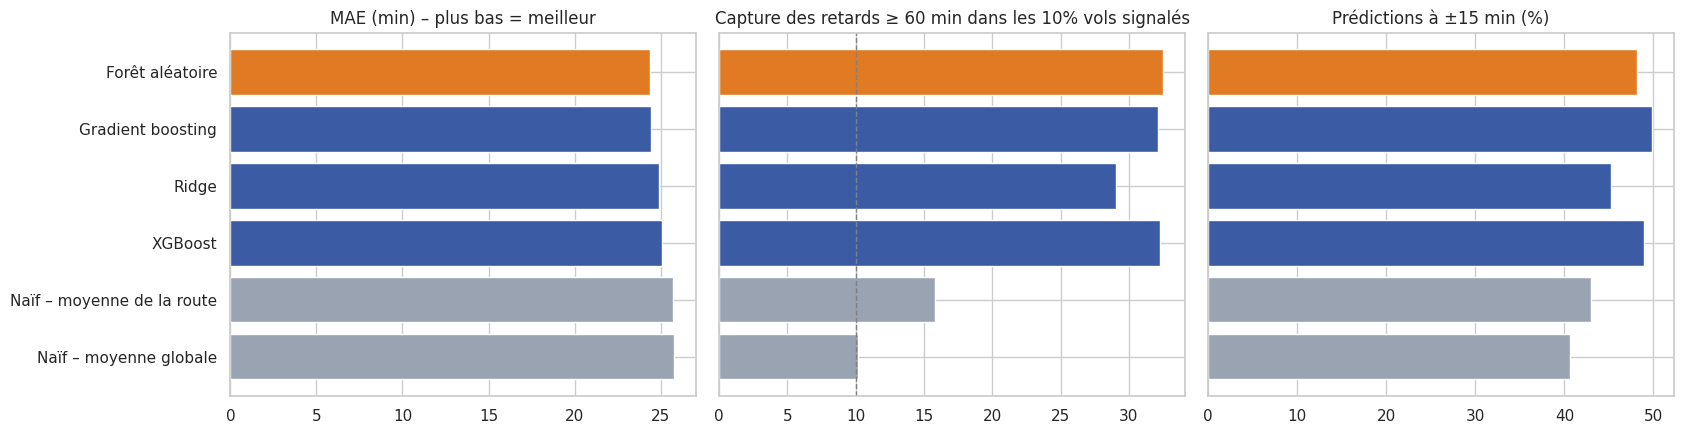

In [31]:
res = pd.DataFrame(resultats)
res["gain MAE vs naïf route"] = ((1 - res["MAE (min)"] / MAE_NAIF) * 100).round(1).astype(str) + " %"
display(res.round(2))

candidats = res[~res["modèle"].str.startswith("Naïf")].sort_values("MAE (min)")
MEILLEUR = candidats.iloc[0]["modèle"]
print(f"Meilleur modèle sur la validation (MAE) : {MEILLEUR}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ordre = res.sort_values("MAE (min)", ascending=False)
couleurs = [GRIS if m.startswith("Naïf") else (ORANGE if m == MEILLEUR else BLEU) for m in ordre["modèle"]]
ax[0].barh(ordre["modèle"], ordre["MAE (min)"], color=couleurs); ax[0].set(title="MAE (min) – plus bas = meilleur")
ax[1].barh(ordre["modèle"], ordre["capture gros retards (%)"], color=couleurs)
ax[1].axvline(PART_SIGNALEE * 100, color="grey", ls="--", lw=1)
ax[1].set(title=f"Capture des retards ≥ {SEUIL_GROS_RETARD} min dans les {PART_SIGNALEE:.0%} vols signalés")
ax[2].barh(ordre["modèle"], ordre["prédictions à ±15 min (%)"], color=couleurs); ax[2].set(title="Prédictions à ±15 min (%)")
for a in ax[1:]: a.set_yticklabels([])
sauver("01_comparaison_modeles")

## 20 bis. Choix de la métrique : comparaison des métriques

Avant de fixer les cibles du contrat d'optimisation, on compare plusieurs métriques de régression sur les mêmes prédictions (jeu de validation) :

- **MAE** : erreur moyenne en minutes ;
- **RMSE** : erreur qui pénalise fortement les grosses erreurs ;
- **R²** : part de la variation des retards expliquée par le modèle ;
- **erreur médiane (MedAE)** : erreur sur un vol « typique » ;
- **MAPE** : erreur en pourcentage du retard réel.

On regarde aussi si les métriques classent les modèles dans le même ordre.

In [32]:
from sklearn.metrics import median_absolute_error

# 1. Forme des retards : pourquoi certaines métriques conviennent mal
y = y_va.to_numpy(float)
print(f"Retards de la validation : moyenne {y.mean():.1f} min, médiane {np.median(y):.1f} min, maximum {y.max():.0f} min")
print(f"Vols en avance ou à l'heure (retard ≤ 0) : {(y <= 0).mean() * 100:.1f} %  –  retard exactement 0 : {(y == 0).mean() * 100:.1f} %")
print("→ Distribution très asymétrique ; la MAPE (division par le retard réel) est impossible quand le retard vaut 0.\n")

# 2. Toutes les métriques, pour chaque modèle
lignes = []
for nom, p in predictions.items():
    lignes.append({
        "modèle": nom,
        "MAE (min)": mean_absolute_error(y, p),
        "RMSE (min)": mean_squared_error(y, p) ** 0.5,
        "RMSE / MAE": mean_squared_error(y, p) ** 0.5 / mean_absolute_error(y, p),
        "R²": r2_score(y, p),
        "erreur médiane (min)": median_absolute_error(y, p),
        "MAPE": "impossible (retards = 0)",
    })
comp_metriques = pd.DataFrame(lignes).sort_values("MAE (min)")
display(comp_metriques.round(2))

# 3. Les métriques classent-elles les modèles de la même façon ?
rangs = pd.DataFrame({
    "rang MAE": comp_metriques["MAE (min)"].rank(),
    "rang RMSE": comp_metriques["RMSE (min)"].rank(),
    "rang R²": comp_metriques["R²"].rank(ascending=False),
    "rang erreur médiane": comp_metriques["erreur médiane (min)"].rank(),
}).astype(int)
rangs.insert(0, "modèle", comp_metriques["modèle"])
display(rangs)

# 4. Tableau de décision : quelle métrique retenir ?
b = comp_metriques.set_index("modèle").loc[MEILLEUR]
choix = pd.DataFrame([
    ["MAE", f"{b['MAE (min)']:.2f} min", "En minutes, facile à comprendre ; peu sensible aux retards extrêmes",
     "Pénalise peu les très grosses erreurs", "Retenue : technique primaire"],
    ["RMSE", f"{b['RMSE (min)']:.2f} min", "Pénalise les grosses erreurs, les plus coûteuses",
     f"Dominée par quelques retards extrêmes (RMSE = {b['RMSE / MAE']:.1f} × MAE)", "Retenue : technique secondaire (garde-fou)"],
    ["R²", f"{b['R²']:.3f}", "Utile pour comparer des modèles entre eux",
     "Peu parlant pour le client ; faible sans le retard au départ (exclu : fuite)", "Non retenue (suivie)"],
    ["Erreur médiane", f"{b['erreur médiane (min)']:.2f} min", "Erreur d'un vol typique",
     "Ignore complètement les gros retards", "Non retenue"],
    ["MAPE", "impossible", "Facile à lire en %",
     f"{(y == 0).mean() * 100:.1f} % des retards valent 0 : division par 0", "Non retenue"],
], columns=["métrique", f"valeur ({MEILLEUR})", "avantage", "limite pour PrédiVol", "décision"])
display(choix)
choix.to_csv("comparaison_metriques.csv", index=False, encoding="utf-8-sig")
print("Tableau enregistré : comparaison_metriques.csv")

Retards de la validation : moyenne 5.6 min, médiane -6.0 min, maximum 3246 min
Vols en avance ou à l'heure (retard ≤ 0) : 64.4 %  –  retard exactement 0 : 1.9 %
→ Distribution très asymétrique ; la MAPE (division par le retard réel) est impossible quand le retard vaut 0.



,modèle,MAE (min),RMSE (min),RMSE / MAE,R²,erreur médiane (min),MAPE
3,Forêt aléatoire,24.36,53.50,2.20,0.06,15.65,impossible (retards = 0)
4,Gradient boosting,24.43,53.58,2.19,0.06,15.07,impossible (retards = 0)
2,Ridge,24.91,54.11,2.17,0.04,16.72,impossible (retards = 0)
5,XGBoost,25.10,54.05,2.15,0.04,15.40,impossible (retards = 0)
1,Naïf – moyenne de la route,25.70,55.27,2.15,-0.00,17.37,impossible (retards = 0)
0,Naïf – moyenne globale,25.78,55.28,2.14,-0.00,17.75,impossible (retards = 0)


,modèle,rang MAE,rang RMSE,rang R²,rang erreur médiane
3,Forêt aléatoire,1,1,1,3
4,Gradient boosting,2,2,2,1
2,Ridge,3,4,4,4
5,XGBoost,4,3,3,2
1,Naïf – moyenne de la route,5,5,5,5
0,Naïf – moyenne globale,6,6,6,6


,métrique,valeur (Forêt aléatoire),avantage,limite pour PrédiVol,décision
0,MAE,24.36 min,"En minutes, facile à comprendre ; peu sensible...",Pénalise peu les très grosses erreurs,Retenue : technique primaire
1,RMSE,53.50 min,"Pénalise les grosses erreurs, les plus coûteuses",Dominée par quelques retards extrêmes (RMSE = ...,Retenue : technique secondaire (garde-fou)
2,R²,0.063,Utile pour comparer des modèles entre eux,Peu parlant pour le client ; faible sans le re...,Non retenue (suivie)
3,Erreur médiane,15.65 min,Erreur d'un vol typique,Ignore complètement les gros retards,Non retenue
4,MAPE,impossible,Facile à lire en %,1.9 % des retards valent 0 : division par 0,Non retenue


Tableau enregistré : comparaison_metriques.csv


**Lecture.** Les retards sont très asymétriques : retard médian de −6 min, mais moyen de 5,6 min, avec des retards extrêmes (jusqu'à 3 246 min ici) ; 64 % des vols arrivent à l'heure ou en avance. La RMSE vaut environ 2,2 fois la MAE pour tous les modèles : elle est dominée par quelques très gros retards. Les métriques ne classent pas tout à fait les modèles de la même façon : la forêt aléatoire est première selon la MAE, la RMSE et le R², mais le gradient boosting est premier selon l'erreur médiane. La MAPE est impossible, car certains retards valent exactement 0 (division par 0).

**Décision :** la MAE est la métrique technique principale (en minutes, compréhensible par les planificateurs, peu sensible aux extrêmes) ; la RMSE est la métrique secondaire, qui sert de garde-fou pour les gros retards.

## 21. Analyse des erreurs du meilleur modèle

Le sujet demande de **comparer les erreurs du modèle** : où se trompe-t-il le plus ? On compare aussi avec le modèle naïf de la route.

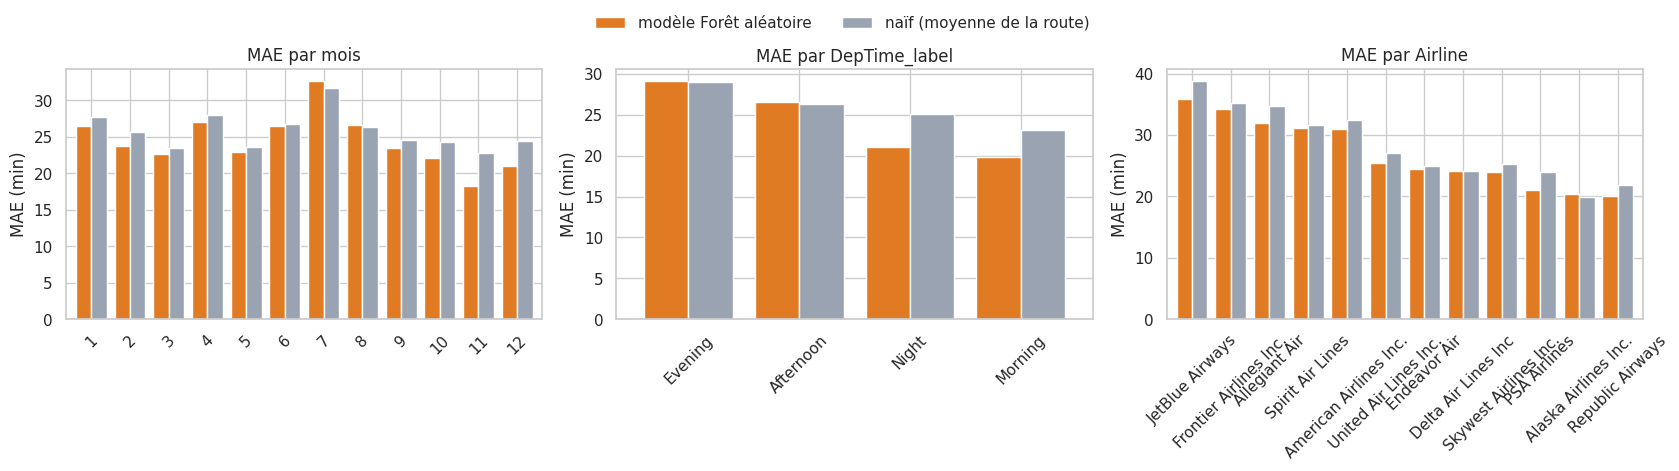

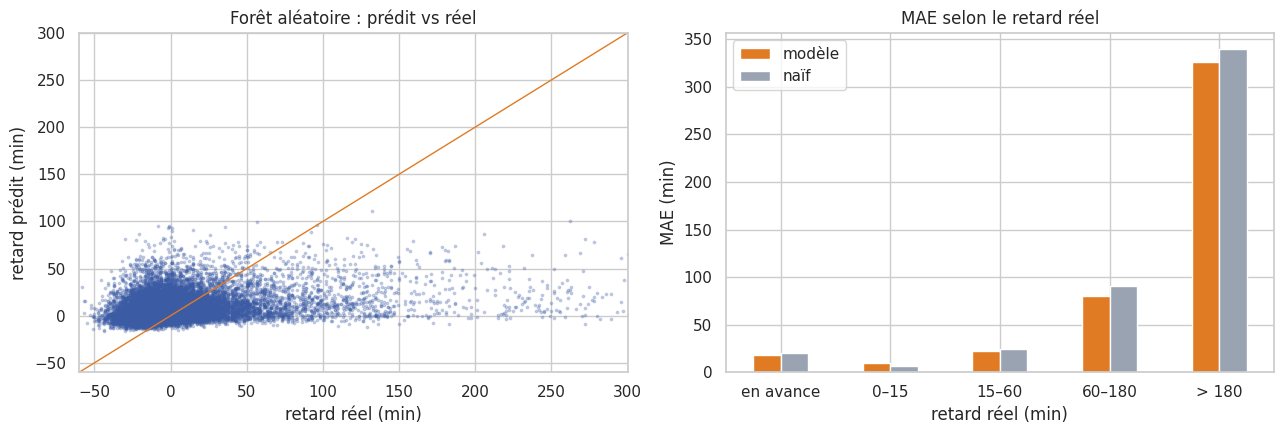

Lecture : le modèle se trompe surtout sur les gros retards, rares et souvent imprévisibles (pannes, orages).


In [33]:
p_best, p_naif = predictions[MEILLEUR], predictions["Naïf – moyenne de la route"]
err = val[[c for c in ["mois", trouver("DepTime_label") or "tranche", trouver("Airline")] if c in val]].copy()
err["erreur modèle"], err["erreur naïf"] = np.abs(y_va.values - p_best), np.abs(y_va.values - p_naif)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, err.columns[:3]):
    g = err.groupby(col)[["erreur modèle", "erreur naïf"]].mean()
    if col != "mois":
        g = g.sort_values("erreur modèle", ascending=False).head(12)
    g.plot.bar(ax=a, color=[ORANGE, GRIS], width=.8, legend=False)
    a.set(title=f"MAE par {col}", ylabel="MAE (min)", xlabel=""); a.tick_params(axis="x", rotation=45)
fig.legend(["modèle " + MEILLEUR, "naïf (moyenne de la route)"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
sauver("02_erreurs_par_segment")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
idx = np.random.default_rng(GRAINE).choice(len(y_va), min(20_000, len(y_va)), replace=False)
ax[0].scatter(y_va.values[idx], p_best[idx], s=3, alpha=.25, color=BLEU)
ax[0].plot([-60, 300], [-60, 300], color=ORANGE, lw=1)
ax[0].set(xlim=(-60, 300), ylim=(-60, 300), title=f"{MEILLEUR} : prédit vs réel", xlabel="retard réel (min)", ylabel="retard prédit (min)")
classes = pd.cut(y_va, [-np.inf, 0, 15, 60, 180, np.inf], labels=["en avance", "0–15", "15–60", "60–180", "> 180"])
pd.DataFrame({"modèle": np.abs(y_va.values - p_best), "naïf": np.abs(y_va.values - p_naif)}).groupby(classes.values).mean() \
  .plot.bar(ax=ax[1], color=[ORANGE, GRIS])
ax[1].set(title="MAE selon le retard réel", xlabel="retard réel (min)", ylabel="MAE (min)"); ax[1].tick_params(axis="x", rotation=0)
sauver("03_predit_vs_reel")
print("Lecture : le modèle se trompe surtout sur les gros retards, rares et souvent imprévisibles (pannes, orages).")

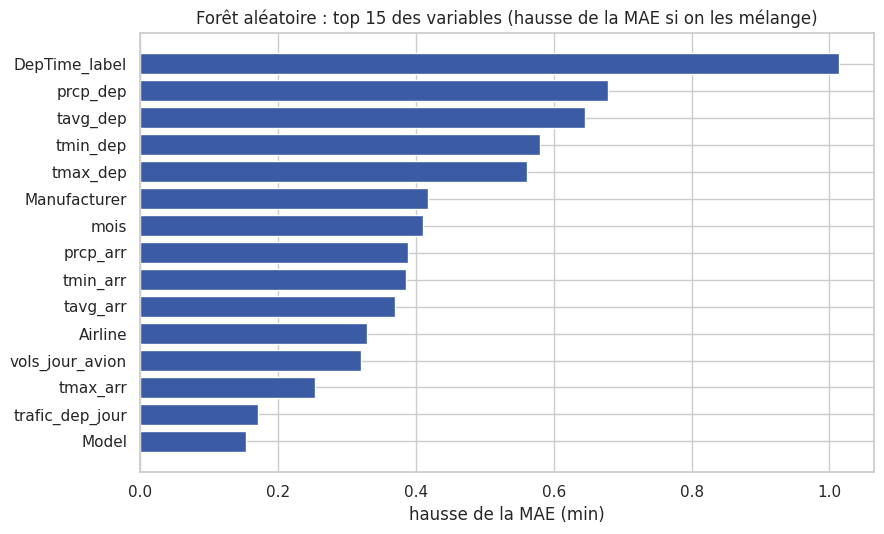

In [34]:
# Variables les plus importantes (importance par permutation sur 20 000 vols de validation)
sous = X_va.sample(min(20_000, len(X_va)), random_state=GRAINE)
imp = permutation_importance(entraines[MEILLEUR], sous, y_va.loc[sous.index], n_repeats=3,
                             scoring="neg_mean_absolute_error", random_state=GRAINE, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=sous.columns).sort_values(ascending=False).head(15)[::-1]
plt.figure(figsize=(9, 5.5)); plt.barh(imp.index, imp.values, color=BLEU)
plt.title(f"{MEILLEUR} : top 15 des variables (hausse de la MAE si on les mélange)"); plt.xlabel("hausse de la MAE (min)")
sauver("04_importance_variables")

## 22. Journal des expériences

Chaque exécution ajoute ses résultats à `journal_experiences.csv` (date, modèle, paramètres, métriques). Ce journal servira au **suivi des expérimentations** pendant l'optimisation.

In [35]:
horodatage = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
journal = res.copy()
journal.insert(0, "date", horodatage)
journal["paramètres"] = [json.dumps(modeles[m].named_steps["mod"].get_params(), default=str)[:500] if m in modeles else ""
                         for m in journal["modèle"]]
journal["vols entraînement"], journal["vols validation"] = len(X_tr), len(X_va)
journal.to_csv("journal_experiences.csv", mode="a", index=False, encoding="utf-8-sig",
               header=not os.path.exists("journal_experiences.csv"))

b = res.set_index("modèle").loc[MEILLEUR]
print("=== Valeurs actuelles pour le contrat d'optimisation (validation) ===")
print(f"Meilleur modèle                     : {MEILLEUR}")
print(f"MAE                                 : {b['MAE (min)']:.2f} min  (naïf route : {MAE_NAIF:.2f} min, gain {b['gain MAE vs naïf route']})")
print(f"RMSE                                : {b['RMSE (min)']:.2f} min")
print(f"R²                                  : {b['R²']:.3f}")
print(f"Capture des retards ≥ {SEUIL_GROS_RETARD} min (top {PART_SIGNALEE:.0%}) : {b['capture gros retards (%)']:.1f} %  (hasard : {PART_SIGNALEE * 100:.0f} %)")
print(f"Prédictions à ±15 min               : {b['prédictions à ±15 min (%)']:.1f} %")
print(f"Prédiction pour 1 000 vols          : {b['prédiction / 1 000 vols (ms)']:.1f} ms")

import shutil
shutil.make_archive("figures_jalon2", "zip", "figures_jalon2")
try:
    from google.colab import files
    for f in ["journal_experiences.csv", "figures_jalon2.zip"]:
        files.download(f)
except Exception:
    print("\nFichiers créés : journal_experiences.csv, figures_jalon2.zip")

=== Valeurs actuelles pour le contrat d'optimisation (validation) ===
Meilleur modèle                     : Forêt aléatoire
MAE                                 : 24.36 min  (naïf route : 25.70 min, gain 5.2 %)
RMSE                                : 53.50 min
R²                                  : 0.063
Capture des retards ≥ 60 min (top 10%) : 32.5 %  (hasard : 10 %)
Prédictions à ±15 min               : 48.1 %
Prédiction pour 1 000 vols          : 11.9 ms


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 23. Suivi des expériences avec MLflow (DagsHub)

In [37]:
# ===== PARAMÈTRES MLFLOW =====
DAGSHUB_UTILISATEUR = "gnichimariem1-cell"
DAGSHUB_DEPOT = "predivol"
NOM_EXPERIENCE = "predivol-modeles-de-base"

import subprocess, sys, os
from getpass import getpass
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mlflow"], check=True)
import mlflow

# Connexion directe au serveur MLflow de DagsHub (le jeton n'est pas écrit dans le notebook)
os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_UTILISATEUR
os.environ["MLFLOW_TRACKING_PASSWORD"] = getpass("Collez votre jeton DagsHub puis Entrée : ")
mlflow.set_tracking_uri(f"https://dagshub.com/{DAGSHUB_UTILISATEUR}/{DAGSHUB_DEPOT}.mlflow")
mlflow.set_experiment(NOM_EXPERIENCE)

for _, ligne in res.iterrows():
    nom = ligne["modèle"]
    with mlflow.start_run(run_name=nom):
        mlflow.set_tags({"projet": "PrédiVol", "type": "naïf" if nom.startswith("Naïf") else "modèle",
                         "meilleur": str(nom == MEILLEUR)})
        if nom in modeles:
            params = modeles[nom].named_steps["mod"].get_params()
            mlflow.log_params({k: str(v)[:250] for k, v in params.items()})
        mlflow.log_params({"taille_echantillon": TAILLE_ECHANTILLON, "separation": "70/15/15 par jour",
                           "vols_entrainement": len(X_tr), "vols_validation": len(X_va)})
        mesures = {"MAE_min": ligne["MAE (min)"], "RMSE_min": ligne["RMSE (min)"], "R2": ligne["R²"],
                   "capture_gros_retards_pct": ligne["capture gros retards (%)"],
                   "predictions_15min_pct": ligne["prédictions à ±15 min (%)"]}
        if not np.isnan(ligne["entraînement (s)"]):
            mesures.update({"entrainement_s": ligne["entraînement (s)"],
                            "prediction_1000_vols_ms": ligne["prédiction / 1 000 vols (ms)"]})
        mlflow.log_metrics(mesures)
        if nom == MEILLEUR:
            for f in ["figures_jalon2.zip", "journal_experiences.csv", "comparaison_metriques.csv"]:
                if os.path.exists(f):
                    mlflow.log_artifact(f)

print(f"{len(res)} expériences envoyées.")
print(f"Interface MLflow : https://dagshub.com/{DAGSHUB_UTILISATEUR}/{DAGSHUB_DEPOT}.mlflow")

Collez votre jeton DagsHub puis Entrée : ··········
🏃 View run Naïf – moyenne globale at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/d5857f9dad3f4f02b8bc6f7699014a54
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Naïf – moyenne de la route at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/36e322cf226745f5a15100f6fc4d21b3
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Ridge at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/4aea262b48b3455da570324ad8d7177a
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View run Forêt aléatoire at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0/runs/0749cef4d1b84798b142ed2a86e28eb4
🧪 View experiment at: https://dagshub.com/gnichimariem1-cell/predivol.mlflow/#/experiments/0
🏃 View r